# TP1 – Manipuler et explorer un fichier d'apprentissage


#### HADBI Safa 
#### HALI Houda 

## 0. Imports et fonctions utilitaires

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from sklearn.preprocessing import MinMaxScaler, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [2]:
# faire la difference entre un fichier .csv et un fichier .arff
def charger(chemin):
    """Ouvre un fichier .csv ou .arff et retourne un DataFrame Pandas propre."""
    if chemin.lower().endswith(".arff"):
        data, meta = arff.loadarff(chemin)
        df = pd.DataFrame(data)
        for c in df.columns:
            if df[c].dtype == object:                      # les chaînes ARFF sont en bytes
                df[c] = df[c].apply(lambda v: v.decode("utf-8") if isinstance(v, bytes) else v)
    else:
        df = pd.read_csv(chemin, sep=None, engine="python", na_values=["?", "NA", "NaN", ""])
    df = df.replace("?", np.nan)
    # convertir en numérique les colonnes qui sont en réalité numériques
    for c in df.columns:
        if df[c].dtype == object:
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() >= 0.9 * df[c].notna().sum():
                df[c] = conv
    return df

# nombre de lignes, colonnes, noms et types

def infos_base(df):
    print("Nombre d'instances (lignes) :", df.shape[0])
    print("Nombre d'attributs (colonnes) :", df.shape[1])
    print("Noms des attributs :", list(df.columns))
    print("\nType de chaque attribut :")
    print(df.dtypes)

# fonctions predefinie pour : min, max, médiane, Q1, Q3, moyenne, mode
def stats_predefinies(df):
    """Min, Max, Médiane, Q1, Q3, Moyenne, Mode avec les fonctions Pandas."""
    num = df.select_dtypes(include=np.number)
    if num.empty:
        return pd.DataFrame({
            "min": [], "max": [], "mediane": [],
            "Q1": [], "Q3": [], "moyenne": [], "mode": []
        }, index=[])
    res = pd.DataFrame({
        "min": num.min(), "max": num.max(), "mediane": num.median(),
        "Q1": num.quantile(0.25), "Q3": num.quantile(0.75),
        "moyenne": num.mean(),
        "mode": df[num.columns].mode().iloc[0],
    })
    return res
   # boîtes à moustaches de tous les attributs

def boxplots(df, titre):
    num = df.select_dtypes(include=np.number)
    if num.empty:
        print(f"Dataset {titre} : aucun attribut numérique pour boxplot.")
        return
    plt.figure(figsize=(max(8, len(num.columns) * 0.9), 6))
    num.boxplot()
    plt.title("Boxplots des attributs – " + titre)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

#matrice de nuages de points
def scatter(df, titre, max_cols=8):
    num = df.select_dtypes(include=np.number).dropna(axis=1, how="all")   
    if num.empty:
        print(f"Dataset {titre} : aucun attribut numérique pour scatter plot.")
        return
    cols = list(num.columns[:max_cols])      # limité pour rester lisible
    pd.plotting.scatter_matrix(num[cols], figsize=(12, 12), diagonal="hist", alpha=0.6)
    plt.suptitle("Scatter plot – " + titre, y=0.92)
    plt.show()
# valeurs manquante
def valeurs_manquantes(df):
    manq = pd.DataFrame({"nb_manquantes": df.isna().sum(),
                         "pourcentage": (df.isna().mean() * 100).round(2)})
    return manq[manq.nb_manquantes > 0]

# remplacer les valeurs manquantes
def imputer(df):
    """Moyenne pour les attributs numériques, mode pour les autres."""
    d = df.copy()
    vides = [c for c in d.columns if d[c].isna().all()]
    if vides:
        print("Colonnes entièrement vides supprimées :", vides)
        d = d.drop(columns=vides)
    for c in d.columns:
        if d[c].isna().any():
            if pd.api.types.is_numeric_dtype(d[c]):
                d[c] = d[c].fillna(d[c].mean())
            else:
                d[c] = d[c].fillna(d[c].mode().iloc[0])
    return d

  #normalisation Min-Max et Z-score
def normaliser_predefini(df):
    num = df.select_dtypes(include=np.number)
    if num.empty:
        return pd.DataFrame(), pd.DataFrame()
    mm = pd.DataFrame(MinMaxScaler().fit_transform(num), columns=num.columns)
    zs = pd.DataFrame(StandardScaler().fit_transform(num), columns=num.columns)
    return mm, zs

## 1. Dataset : diabetes  (`diabetes.arff`)

### 1.1 Lecture et informations de base

In [3]:
df_diabetes = charger("diabetes.arff")
display(df_diabetes.head())
infos_base(df_diabetes)

,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6.0,148.0,72.0,35.0,0.0,33.6,0.627,50.0,tested_positive
1,1.0,85.0,66.0,29.0,0.0,26.6,0.351,31.0,tested_negative
2,8.0,183.0,64.0,0.0,0.0,23.3,0.672,32.0,tested_positive
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,tested_negative
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,tested_positive


Nombre d'instances (lignes) : 768
Nombre d'attributs (colonnes) : 9
Noms des attributs : ['preg', 'plas', 'pres', 'skin', 'insu', 'mass', 'pedi', 'age', 'class']

Type de chaque attribut :
preg     float64
plas     float64
pres     float64
skin     float64
insu     float64
mass     float64
pedi     float64
age      float64
class        str
dtype: object


### 1.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode

In [4]:
stats_diabetes = stats_predefinies(df_diabetes)
stats_diabetes

,min,max,mediane,Q1,Q3,moyenne,mode
preg,0.000,17.00,3.0000,1.00000,6.00000,3.845052,1.000
plas,0.000,199.00,117.0000,99.00000,140.25000,120.894531,99.000
pres,0.000,122.00,72.0000,62.00000,80.00000,69.105469,70.000
skin,0.000,99.00,23.0000,0.00000,32.00000,20.536458,0.000
insu,0.000,846.00,30.5000,0.00000,127.25000,79.799479,0.000
mass,0.000,67.10,32.0000,27.30000,36.60000,31.992578,32.000
pedi,0.078,2.42,0.3725,0.24375,0.62625,0.471876,0.254
age,21.000,81.00,29.0000,24.00000,41.00000,33.240885,22.000


### 1.2.2 manuellement :

In [5]:
def min_manuel(s):
    x = [v for v in s if not math.isnan(v)]
    m = x[0]
    for v in x:
        if v < m: m = v
    return m

def max_manuel(s):
    x = [v for v in s if not math.isnan(v)]
    m = x[0]
    for v in x:
        if v > m: m = v
    return m

def moyenne_manuelle(s):
    x = [v for v in s if not math.isnan(v)]
    return sum(x) / len(x)

def mediane_manuelle(s):
    x = sorted(v for v in s if not math.isnan(v))
    n = len(x)
    if n % 2 == 1:
        return x[n // 2]
    return (x[n // 2 - 1] + x[n // 2]) / 2

def quartile_manuel(s, p):
    """Quantile p (0.25 -> Q1, 0.75 -> Q3), interpolation linéaire (comme Pandas)."""
    x = sorted(v for v in s if not math.isnan(v))
    pos = (len(x) - 1) * p
    bas = math.floor(pos)
    haut = math.ceil(pos)
    return x[bas] + (x[haut] - x[bas]) * (pos - bas)

def mode_manuel(s):
    comptage = {}
    for v in s:
        if not (isinstance(v, float) and math.isnan(v)):
            comptage[v] = comptage.get(v, 0) + 1
    maxi = max(comptage.values())
    return min(v for v, c in comptage.items() if c == maxi)   # plus petite valeur en cas d'égalité

num_diabetes = df_diabetes.select_dtypes(include=np.number)
stats_diabetes_manuel = pd.DataFrame({
    "min": {c: min_manuel(num_diabetes[c]) for c in num_diabetes},
    "max": {c: max_manuel(num_diabetes[c]) for c in num_diabetes},
    "mediane": {c: mediane_manuelle(num_diabetes[c]) for c in num_diabetes},
    "Q1": {c: quartile_manuel(num_diabetes[c], 0.25) for c in num_diabetes},
    "Q3": {c: quartile_manuel(num_diabetes[c], 0.75) for c in num_diabetes},
    "moyenne": {c: moyenne_manuelle(num_diabetes[c]) for c in num_diabetes},
    "mode": {c: mode_manuel(num_diabetes[c]) for c in num_diabetes},
})
display(stats_diabetes_manuel)
print("Identique aux fonctions prédéfinies ?",
      np.allclose(stats_diabetes_manuel.values.astype(float), stats_diabetes.values.astype(float)))

,min,max,mediane,Q1,Q3,moyenne,mode
preg,0.000,17.00,3.0000,1.00000,6.00000,3.845052,1.000
plas,0.000,199.00,117.0000,99.00000,140.25000,120.894531,99.000
pres,0.000,122.00,72.0000,62.00000,80.00000,69.105469,70.000
skin,0.000,99.00,23.0000,0.00000,32.00000,20.536458,0.000
insu,0.000,846.00,30.5000,0.00000,127.25000,79.799479,0.000
mass,0.000,67.10,32.0000,27.30000,36.60000,31.992578,32.000
pedi,0.078,2.42,0.3725,0.24375,0.62625,0.471876,0.254
age,21.000,81.00,29.0000,24.00000,41.00000,33.240885,22.000


Identique aux fonctions prédéfinies ? True


### 1.3 Boxplots (tous les attributs sur le même graphique)

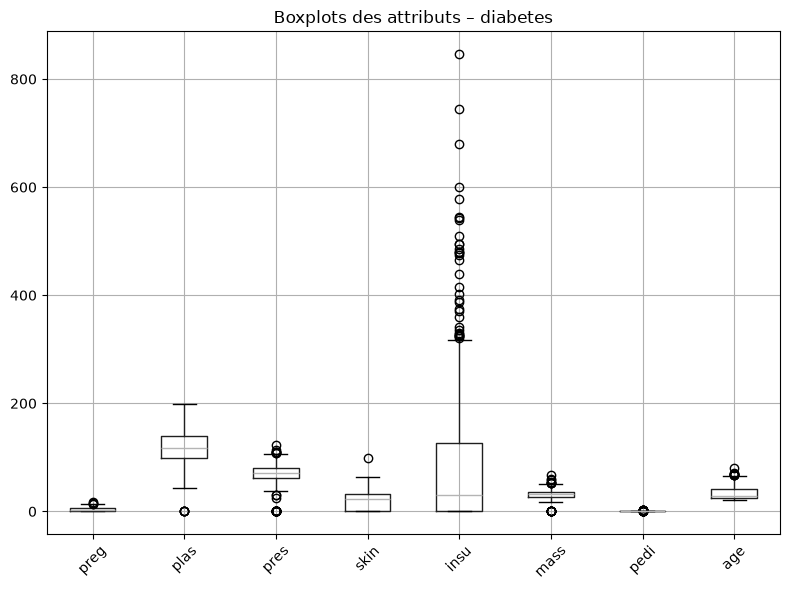

In [6]:
boxplots(df_diabetes, "diabetes")

### 1.4 Scatter plot

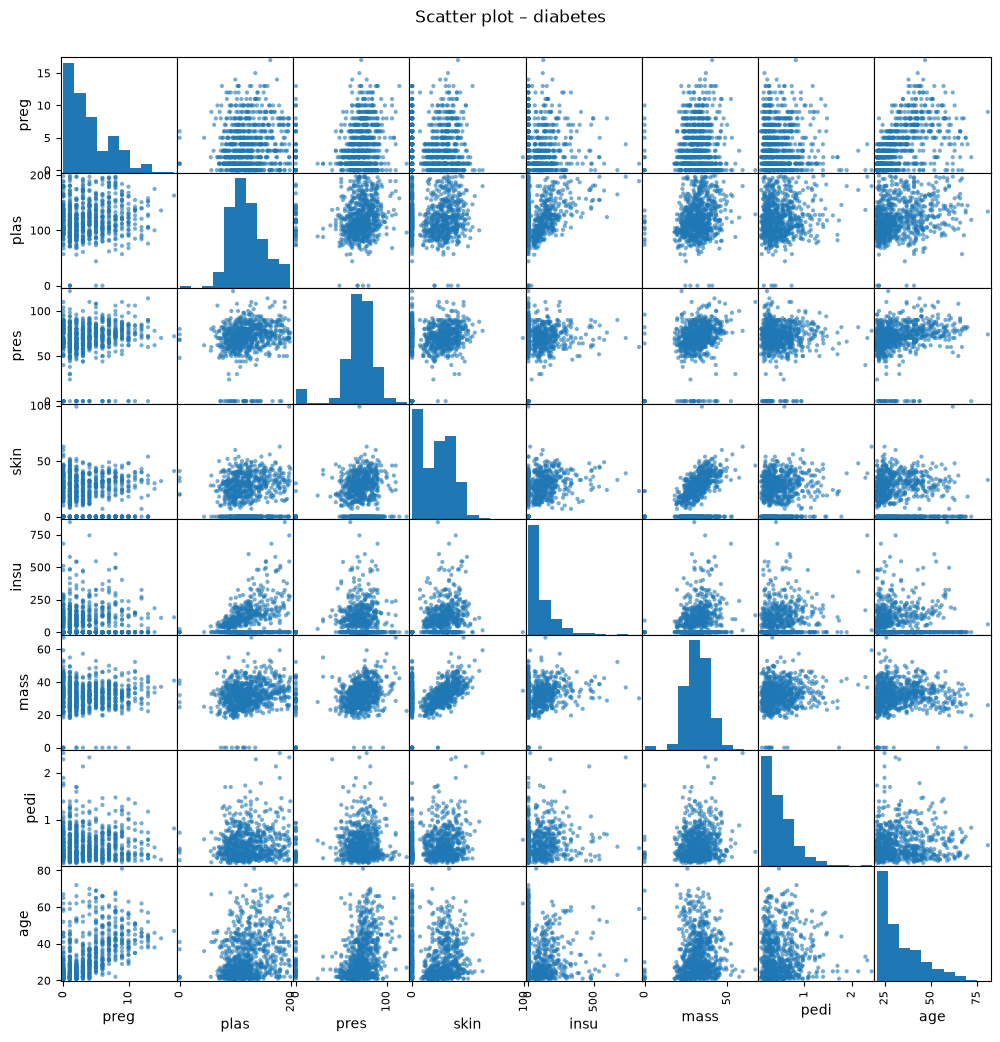

In [7]:
scatter(df_diabetes, "diabetes")

### 1.5 Valeurs manquantes : identification et remplacement

In [8]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_diabetes))
df_diabetes_imp = imputer(df_diabetes)          # moyenne (numérique) / mode (catégoriel)
print("Total de valeurs manquantes après :", df_diabetes_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage


Total de valeurs manquantes après : 0


### 1.6 Normalisation (Min-Max et Z-score)

In [9]:
mm_diabetes, zs_diabetes = normaliser_predefini(df_diabetes_imp)
print("Min-Max :"); display(mm_diabetes.head())
print("Z-score :"); display(zs_diabetes.head())

Min-Max :


,preg,plas,pres,skin,insu,mass,pedi,age
0,0.352941,0.743719,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333
1,0.058824,0.427136,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667
2,0.470588,0.919598,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333
3,0.058824,0.447236,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000
4,0.000000,0.688442,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000


Z-score :


,preg,plas,pres,skin,insu,mass,pedi,age
0,0.639947,0.848324,0.149641,0.907270,-0.692891,0.204013,0.468492,1.425995
1,-0.844885,-1.123396,-0.160546,0.530902,-0.692891,-0.684422,-0.365061,-0.190672
2,1.233880,1.943724,-0.263941,-1.288212,-0.692891,-1.103255,0.604397,-0.105584
3,-0.844885,-0.998208,-0.160546,0.154533,0.123302,-0.494043,-0.920763,-1.041549
4,-1.141852,0.504055,-1.504687,0.907270,0.765836,1.409746,5.484909,-0.020496


### 3.6 bis – Normalisation **manuelle**

In [10]:
num_h = df_diabetes_imp.select_dtypes(include=np.number)

# Min-Max : x' = (x - min) / (max - min)
mm_diabetes_manuel = num_h.copy()
for c in num_h:
    mn, mx = min_manuel(num_h[c]), max_manuel(num_h[c])
    mm_diabetes_manuel[c] = (num_h[c] - mn) / (mx - mn)

# Z-score : x' = (x - moyenne) / écart-type  (écart-type de la population, comme StandardScaler)
zs_diabetes_manuel = num_h.copy()
for c in num_h:
    mu = moyenne_manuelle(num_h[c])
    sigma = math.sqrt(sum((v - mu) ** 2 for v in num_h[c]) / len(num_h[c]))
    zs_diabetes_manuel[c] = (num_h[c] - mu) / sigma

print("Min-Max manuel :"); display(mm_diabetes_manuel.head())
print("Z-score manuel :"); display(zs_diabetes_manuel.head())
print("Min-Max identique au prédéfini ?", np.allclose(mm_diabetes_manuel.values, mm_diabetes.values))
print("Z-score identique au prédéfini ?", np.allclose(zs_diabetes_manuel.values, zs_diabetes.values))

Min-Max manuel :


,preg,plas,pres,skin,insu,mass,pedi,age
0,0.352941,0.743719,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333
1,0.058824,0.427136,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667
2,0.470588,0.919598,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333
3,0.058824,0.447236,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000
4,0.000000,0.688442,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000


Z-score manuel :


,preg,plas,pres,skin,insu,mass,pedi,age
0,0.639947,0.848324,0.149641,0.907270,-0.692891,0.204013,0.468492,1.425995
1,-0.844885,-1.123396,-0.160546,0.530902,-0.692891,-0.684422,-0.365061,-0.190672
2,1.233880,1.943724,-0.263941,-1.288212,-0.692891,-1.103255,0.604397,-0.105584
3,-0.844885,-0.998208,-0.160546,0.154533,0.123302,-0.494043,-0.920763,-1.041549
4,-1.141852,0.504055,-1.504687,0.907270,0.765836,1.409746,5.484909,-0.020496


Min-Max identique au prédéfini ? True
Z-score identique au prédéfini ? True


## 2. Dataset : ecoli  (`ecoli.csv`)

### 2.1 Lecture et informations de base

In [11]:
df_ecoli = pd.read_csv("ecoli.csv", sep=None, engine="python", header=None,
                       names=["mcg", "gvh", "lip", "chg", "aac", "alm1", "alm2", "class"])
display(df_ecoli.head())
infos_base(df_ecoli)

,mcg,gvh,lip,chg,aac,alm1,alm2,class
0,0.49,0.29,0.48,0.5,0.56,0.24,0.35,0
1,0.07,0.40,0.48,0.5,0.54,0.35,0.44,0
2,0.56,0.40,0.48,0.5,0.49,0.37,0.46,0
3,0.59,0.49,0.48,0.5,0.52,0.45,0.36,0
4,0.23,0.32,0.48,0.5,0.55,0.25,0.35,0


Nombre d'instances (lignes) : 336
Nombre d'attributs (colonnes) : 8
Noms des attributs : ['mcg', 'gvh', 'lip', 'chg', 'aac', 'alm1', 'alm2', 'class']

Type de chaque attribut :
mcg      float64
gvh      float64
lip      float64
chg      float64
aac      float64
alm1     float64
alm2     float64
class      int64
dtype: object


### 2.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode

In [12]:
stats_ecoli = stats_predefinies(df_ecoli)
stats_ecoli

,min,max,mediane,Q1,Q3,moyenne,mode
mcg,0.00,0.89,0.500,0.34,0.6625,0.500060,0.63
gvh,0.16,1.00,0.470,0.40,0.5700,0.500000,0.51
lip,0.48,1.00,0.480,0.48,0.4800,0.495476,0.48
chg,0.50,1.00,0.500,0.50,0.5000,0.501488,0.50
aac,0.00,0.88,0.495,0.42,0.5700,0.500030,0.42
alm1,0.03,1.00,0.455,0.33,0.7100,0.500179,0.35
alm2,0.00,0.99,0.430,0.35,0.7100,0.499732,0.39
class,0.00,4.00,1.000,0.00,2.0000,1.303571,0.00


### 2.3 Boxplots (tous les attributs sur le même graphique)

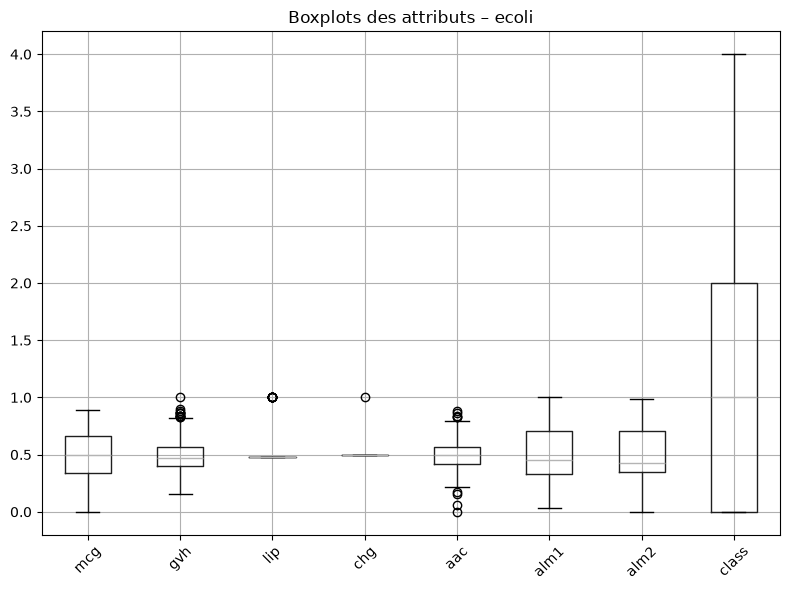

In [13]:
boxplots(df_ecoli, "ecoli")

### 2.4 Scatter plot

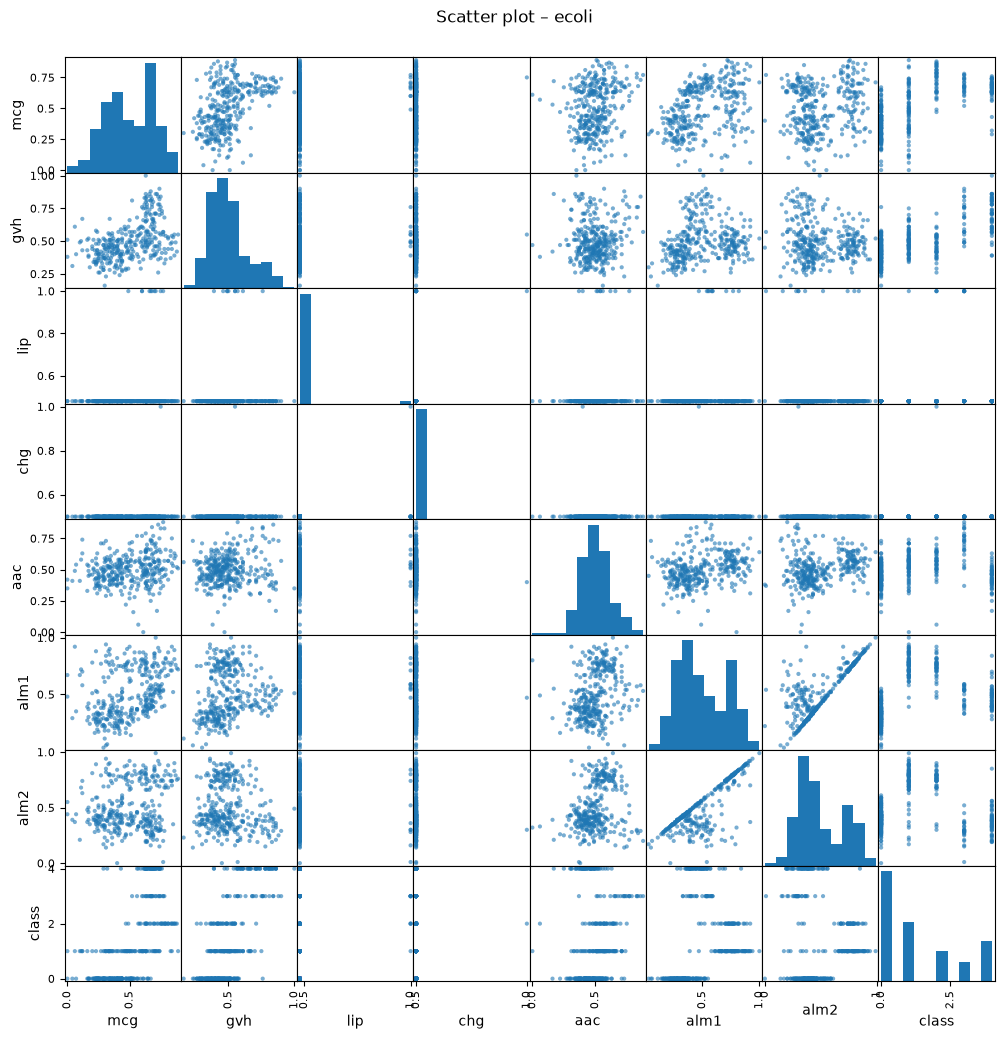

In [14]:
scatter(df_ecoli, "ecoli")

### 2.5 Valeurs manquantes : identification et remplacement

In [15]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_ecoli))
df_ecoli_imp = imputer(df_ecoli)          # moyenne (numérique) / mode (catégoriel)
print("Total de valeurs manquantes après :", df_ecoli_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage


Total de valeurs manquantes après : 0


### 2.6 Normalisation (Min-Max et Z-score)

In [16]:
mm_ecoli, zs_ecoli = normaliser_predefini(df_ecoli_imp)
print("Min-Max :"); display(mm_ecoli.head())
print("Z-score :"); display(zs_ecoli.head())

Min-Max :


,mcg,gvh,lip,chg,aac,alm1,alm2,class
0,0.550562,0.154762,0.0,0.0,0.636364,0.216495,0.353535,0.0
1,0.078652,0.285714,0.0,0.0,0.613636,0.329897,0.444444,0.0
2,0.629213,0.285714,0.0,0.0,0.556818,0.350515,0.464646,0.0
3,0.662921,0.392857,0.0,0.0,0.590909,0.432990,0.363636,0.0
4,0.258427,0.190476,0.0,0.0,0.625000,0.226804,0.353535,0.0


Z-score :


,mcg,gvh,lip,chg,aac,alm1,alm2,class
0,-0.051761,-1.419531,-0.175142,-0.054636,0.490781,-1.207717,-0.716084,-0.891106
1,-2.212876,-0.675967,-0.175142,-0.054636,0.327106,-0.697111,-0.285665,-0.891106
2,0.308424,-0.675967,-0.175142,-0.054636,-0.082081,-0.604273,-0.190016,-0.891106
3,0.462790,-0.067597,-0.175142,-0.054636,0.163431,-0.232923,-0.668259,-0.891106
4,-1.389594,-1.216741,-0.175142,-0.054636,0.408944,-1.161299,-0.716084,-0.891106


## 3. Dataset : heart  (`heart.csv`)

### 3.1 Lecture et informations de base

In [17]:
df_heart = charger("heart.csv")
display(df_heart)
infos_base(df_heart)

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,60,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,35,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,55,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,56,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284,60,1,0,140,207,0,0,138,1,1.9,2,1,3,0
285,46,1,0,140,311,0,1,120,1,1.8,1,2,3,0
286,59,1,3,134,204,0,1,162,0,0.8,2,2,2,0
287,54,1,1,154,232,0,0,164,0,0.0,2,1,2,0


Nombre d'instances (lignes) : 289
Nombre d'attributs (colonnes) : 14
Noms des attributs : ['age', 'sex', 'cp', 'trtbps', 'chol', 'fbs', 'restecg', 'thalachh', 'exng', 'oldpeak', 'slp', 'caa', 'thall', 'output']

Type de chaque attribut :
age           int64
sex           int64
cp            int64
trtbps        int64
chol          int64
fbs           int64
restecg       int64
thalachh      int64
exng          int64
oldpeak     float64
slp           int64
caa           int64
thall         int64
output        int64
dtype: object


### 3.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode (fonctions prédéfinies)

In [18]:
stats_heart = stats_predefinies(df_heart)
stats_heart

,min,max,mediane,Q1,Q3,moyenne,mode
age,29.0,77.0,54.0,47.0,60.0,54.010381,54.0
sex,0.0,1.0,1.0,0.0,1.0,0.678201,1.0
cp,0.0,3.0,1.0,0.0,2.0,1.020761,0.0
trtbps,94.0,200.0,130.0,120.0,140.0,131.377163,120.0
chol,126.0,564.0,243.0,212.0,276.0,247.961938,204.0
fbs,0.0,1.0,0.0,0.0,0.0,0.145329,0.0
restecg,0.0,2.0,1.0,0.0,1.0,0.515571,1.0
thalachh,71.0,202.0,154.0,136.0,168.0,150.231834,162.0
exng,0.0,1.0,0.0,0.0,1.0,0.318339,0.0
oldpeak,0.0,6.2,0.6,0.0,1.6,1.007612,0.0


### 3.3 Boxplots (tous les attributs sur le même graphique)

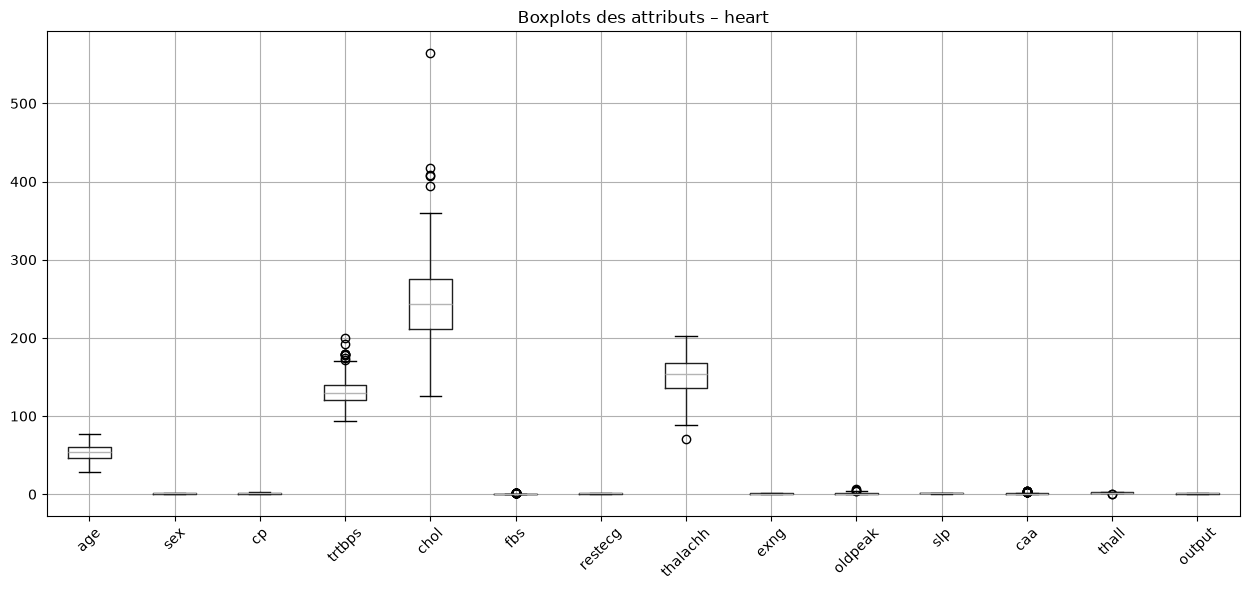

In [19]:
boxplots(df_heart, "heart")

### 3.4 Scatter plot

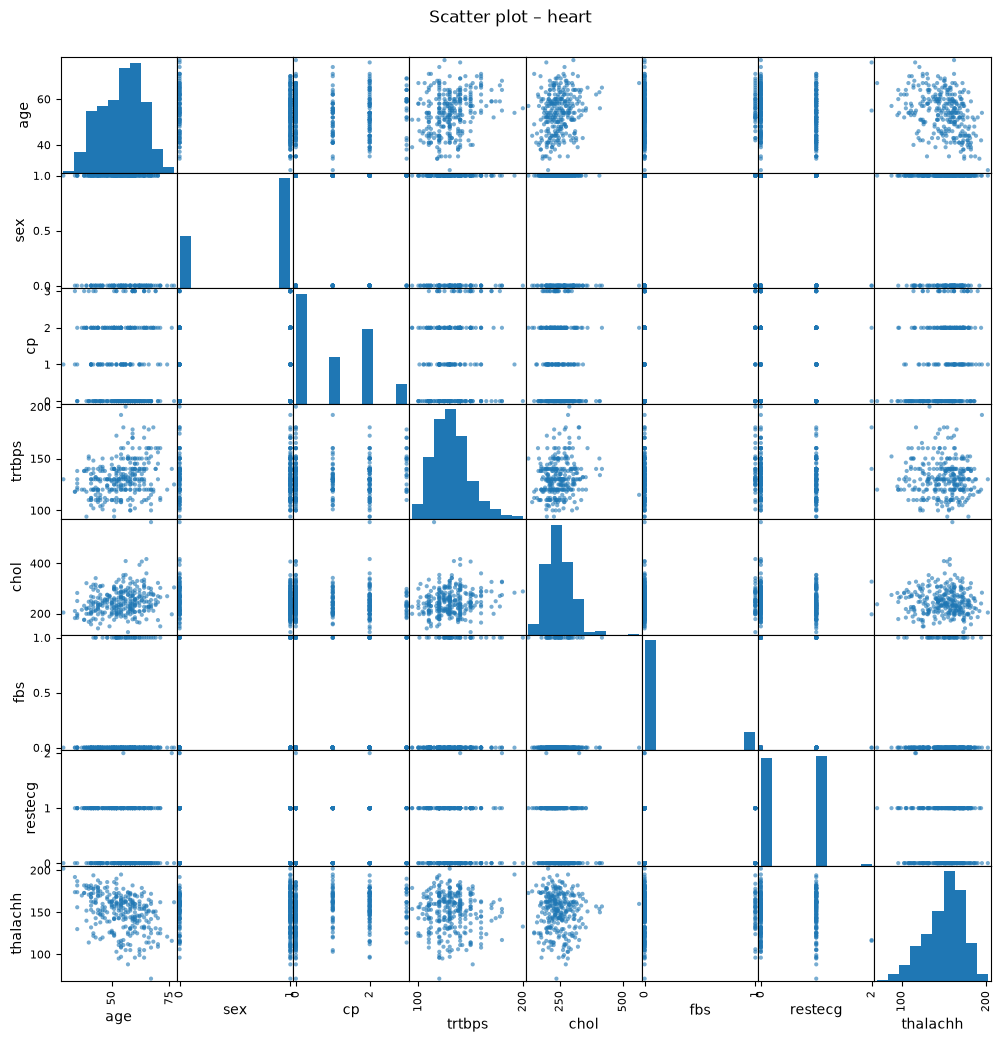

In [20]:
scatter(df_heart, "heart")

### 3.5 Valeurs manquantes : identification et remplacement

In [21]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_heart))
df_heart_imp = imputer(df_heart)          # moyenne (numérique) / mode (catégoriel)
print("Total de valeurs manquantes après :", df_heart_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage


Total de valeurs manquantes après : 0


### 3.6 Normalisation (Min-Max et Z-score) – fonctions prédéfinies

In [22]:
mm_heart, zs_heart = normaliser_predefini(df_heart_imp)
print("Min-Max :"); display(mm_heart.head())
print("Z-score :"); display(zs_heart.head())

Min-Max :


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,0.645833,1.0,1.000000,0.481132,0.244292,1.0,0.0,0.603053,0.0,0.370968,0.0,0.0,0.333333,1.0
1,0.125000,1.0,0.666667,0.339623,0.283105,0.0,0.5,0.885496,0.0,0.564516,0.0,0.0,0.666667,1.0
2,0.250000,0.0,0.333333,0.339623,0.178082,0.0,0.0,0.770992,0.0,0.225806,1.0,0.0,0.666667,1.0
3,0.541667,1.0,0.333333,0.245283,0.251142,0.0,0.5,0.816794,0.0,0.129032,1.0,0.0,0.666667,1.0
4,0.562500,0.0,0.000000,0.245283,0.520548,0.0,0.5,0.702290,1.0,0.096774,1.0,0.0,0.666667,1.0


Z-score :


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,0.657008,0.688832,1.930187,0.778978,-0.290484,2.425068,-1.004193,-0.010141,-0.683378,1.142161,-2.317087,-0.698261,-2.209526,0.8669
1,-2.085271,0.688832,0.954970,-0.078749,0.039569,-0.412360,0.943537,1.608406,-0.683378,2.202673,-2.317087,-0.698261,-0.529123,0.8669
2,-1.427124,-1.451732,-0.020247,-0.078749,-0.853516,-0.412360,-1.004193,0.952238,-0.683378,0.346776,0.949440,-0.698261,-0.529123,0.8669
3,0.108553,0.688832,-0.020247,-0.650566,-0.232240,-0.412360,0.943537,1.214706,-0.683378,-0.183480,0.949440,-0.698261,-0.529123,0.8669
4,0.218244,-1.451732,-0.995463,-0.650566,2.058717,-0.412360,0.943537,0.558538,1.463320,-0.360232,0.949440,-0.698261,-0.529123,0.8669


## 4. Dataset : hepatitis  (` hepatitis.csv`)

### 4.1 Lecture et informations de base

In [23]:
df_hepatitis = charger("hepatitis.csv")
display(df_hepatitis)
infos_base(df_hepatitis)

,class,age,sex,steroid,antivirals,fatigue,malaise,anorexia,liver_big,liver_firm,spleen_palable,spiders,ascites,varices,bilirubin,alk_phosphate,sgot,albumin,protime,histology
0,2,30,2,1,2,2,2,2,1,2,2,2,2,2,1.0,85,18,4.0,61,1
1,2,50,1,1,2,1,2,2,1,2,2,2,2,2,0.9,135,42,3.5,61,1
2,2,78,1,2,2,1,2,2,2,2,2,2,2,2,0.7,96,32,4.0,61,1
3,2,34,1,2,2,2,2,2,2,2,2,2,2,2,1.0,105,200,4.0,61,1
4,2,34,1,2,2,2,2,2,2,2,2,2,2,2,0.9,95,28,4.0,75,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,1,46,1,2,2,1,1,1,2,1,2,1,1,1,7.6,105,242,3.3,50,2
138,2,44,1,2,2,1,2,2,2,1,2,2,2,2,0.9,126,142,4.3,61,2
139,2,61,1,1,2,1,1,2,1,2,2,1,2,2,0.8,75,20,4.1,61,2
140,2,53,2,1,2,1,2,2,2,2,1,1,2,1,1.5,81,19,4.1,48,2


Nombre d'instances (lignes) : 142
Nombre d'attributs (colonnes) : 20
Noms des attributs : ['class', 'age', 'sex', 'steroid', 'antivirals', 'fatigue', 'malaise', 'anorexia', 'liver_big', 'liver_firm', 'spleen_palable', 'spiders', 'ascites', 'varices', 'bilirubin', 'alk_phosphate', 'sgot', 'albumin', 'protime', 'histology']

Type de chaque attribut :
class               int64
age                 int64
sex                 int64
steroid             int64
antivirals          int64
fatigue             int64
malaise             int64
anorexia            int64
liver_big           int64
liver_firm          int64
spleen_palable      int64
spiders             int64
ascites             int64
varices             int64
bilirubin         float64
alk_phosphate       int64
sgot                int64
albumin           float64
protime             int64
histology           int64
dtype: object


### 4.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode

In [24]:
stats_hepatitis = stats_predefinies(df_hepatitis)
stats_hepatitis

,min,max,mediane,Q1,Q3,moyenne,mode
class,1.0,2.0,2.0,2.00,2.00,1.816901,2.0
age,7.0,78.0,39.0,32.00,50.00,40.816901,30.0
sex,1.0,2.0,1.0,1.00,1.00,1.105634,1.0
steroid,1.0,2.0,2.0,1.00,2.00,1.514085,2.0
antivirals,1.0,2.0,2.0,2.00,2.00,1.838028,2.0
fatigue,1.0,2.0,1.0,1.00,2.00,1.359155,1.0
malaise,1.0,2.0,2.0,1.00,2.00,1.619718,2.0
anorexia,1.0,2.0,2.0,2.00,2.00,1.795775,2.0
liver_big,1.0,2.0,2.0,2.00,2.00,1.823944,2.0
liver_firm,1.0,2.0,2.0,1.00,2.00,1.584507,2.0


### 4.3 Boxplots (tous les attributs sur le même graphique)

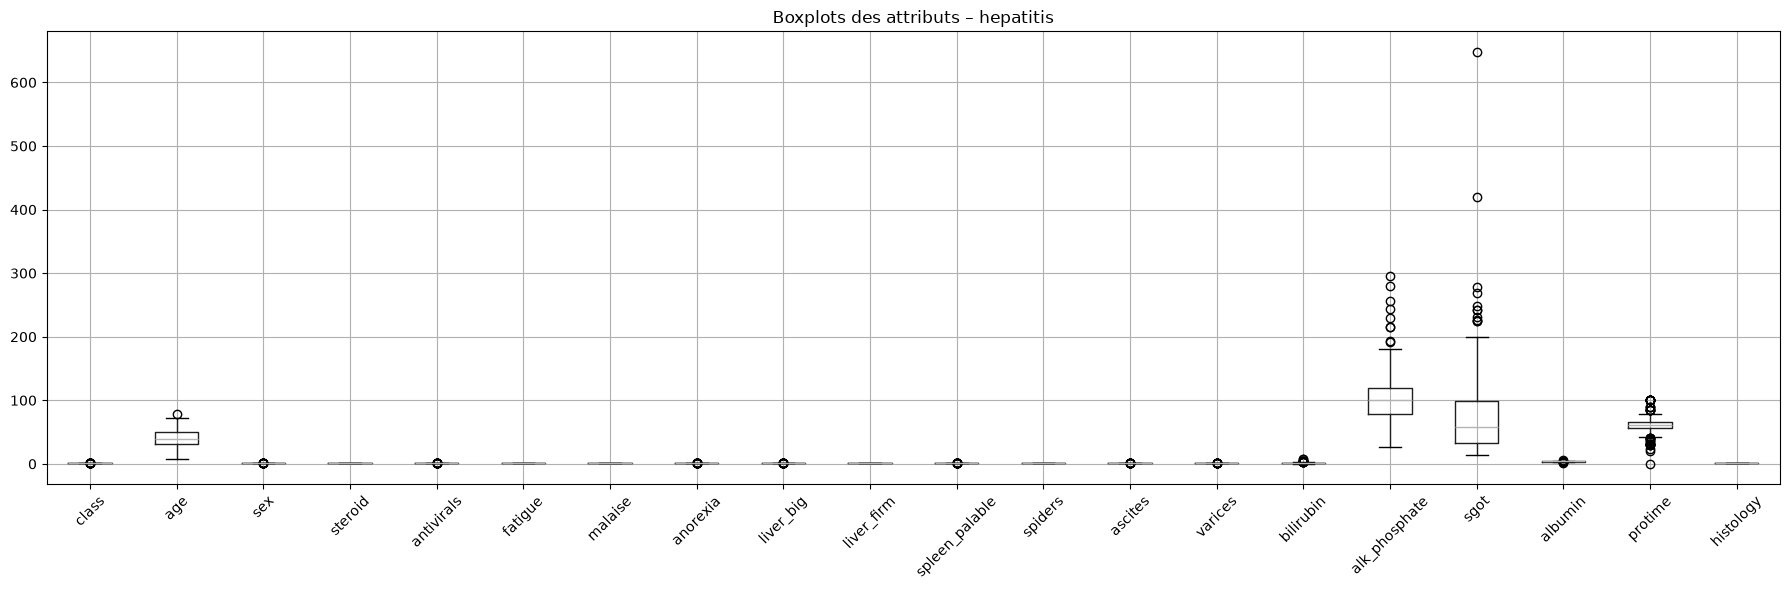

In [25]:
boxplots(df_hepatitis, "hepatitis")

### 4.4 Scatter plot

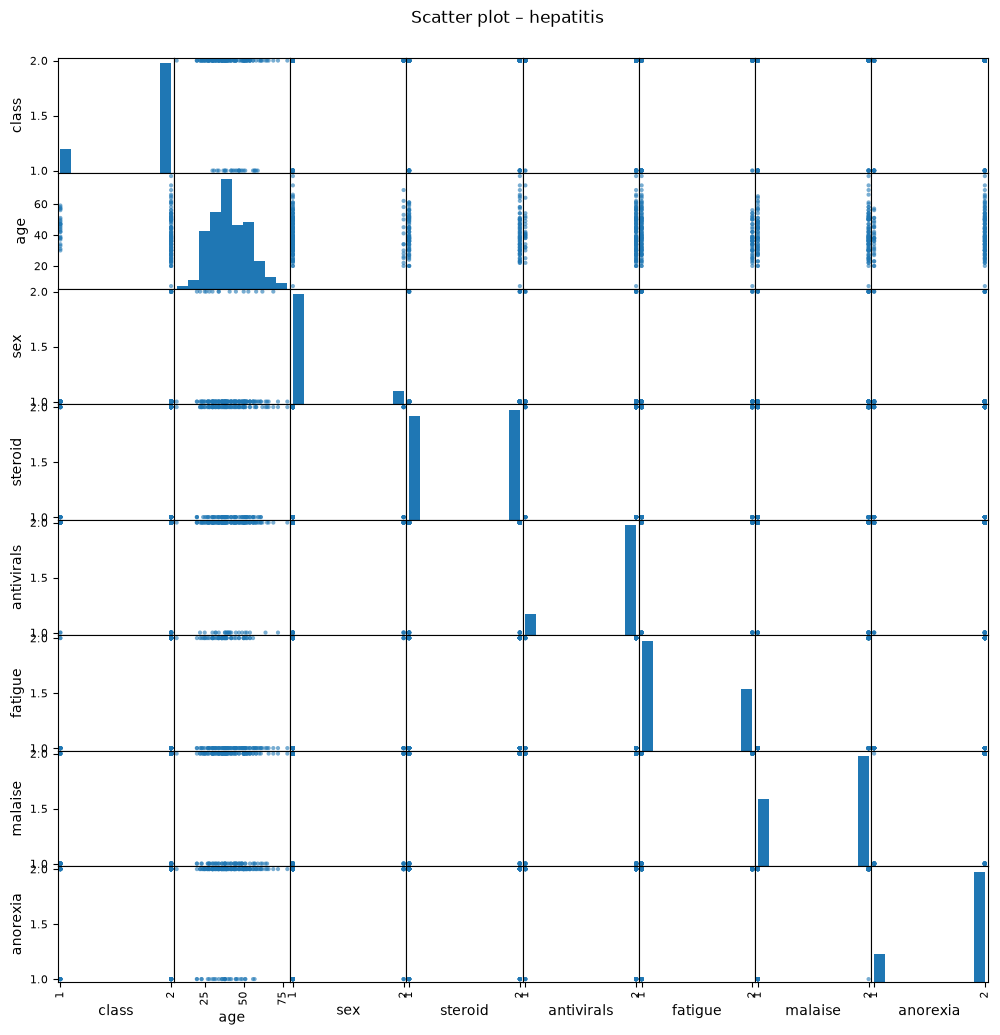

In [26]:
scatter(df_hepatitis, "hepatitis")

### 4.5 Valeurs manquantes : identification et remplacement

In [27]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_hepatitis))
df_hepatitis_imp = imputer(df_hepatitis)          # moyenne (numérique) / mode (catégoriel)
print("Total de valeurs manquantes après :", df_hepatitis_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage


Total de valeurs manquantes après : 0


### 4.6 Normalisation (Min-Max et Z-score)

In [28]:
mm_hepatitis, zs_hepatitis = normaliser_predefini(df_hepatitis_imp)
print("Min-Max :"); display(mm_hepatitis.head())
print("Z-score :"); display(zs_hepatitis.head())

Min-Max :


,class,age,sex,steroid,antivirals,fatigue,malaise,anorexia,liver_big,liver_firm,spleen_palable,spiders,ascites,varices,bilirubin,alk_phosphate,sgot,albumin,protime,histology
0,1.0,0.323944,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.090909,0.219331,0.006309,0.441860,0.61,0.0
1,1.0,0.605634,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.077922,0.405204,0.044164,0.325581,0.61,0.0
2,1.0,1.000000,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.051948,0.260223,0.028391,0.441860,0.61,0.0
3,1.0,0.380282,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.090909,0.293680,0.293375,0.441860,0.61,0.0
4,1.0,0.380282,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.077922,0.256506,0.022082,0.441860,0.75,0.0


Z-score :


,class,age,sex,steroid,antivirals,fatigue,malaise,anorexia,liver_big,liver_firm,spleen_palable,spiders,ascites,varices,bilirubin,alk_phosphate,sgot,albumin,protime,histology
0,0.473432,-0.890559,2.909754,-1.028577,0.439633,1.335782,0.783349,0.506594,-2.163331,0.843115,0.484544,0.703375,0.368782,0.368782,-0.329451,-0.437381,-0.797631,0.275208,-0.039935,-0.893011
1,0.473432,0.756048,-0.343672,-1.028577,0.439633,-0.748625,0.783349,0.506594,-2.163331,0.843115,0.484544,0.703375,0.368782,0.368782,-0.415479,0.621762,-0.505401,-0.536582,-0.039935,-0.893011
2,0.473432,3.061298,-0.343672,0.972217,0.439633,-0.748625,0.783349,0.506594,0.462250,0.843115,0.484544,0.703375,0.368782,0.368782,-0.587535,-0.204370,-0.627163,0.275208,-0.039935,-0.893011
3,0.473432,-0.561238,-0.343672,0.972217,0.439633,1.335782,0.783349,0.506594,0.462250,0.843115,0.484544,0.703375,0.368782,0.368782,-0.329451,-0.013724,1.418449,0.275208,-0.039935,-0.893011
4,0.473432,-0.561238,-0.343672,0.972217,0.439633,1.335782,0.783349,0.506594,0.462250,0.843115,0.484544,0.703375,0.368782,0.368782,-0.415479,-0.225553,-0.675869,0.275208,0.753972,-0.893011


## 5. Dataset : hepatitisequilibre  (`hepatitisequilibre.arff`)

### 5.1 Lecture et informations de base

In [29]:
df_hepatitisequilibre = charger("hepatitisequilibre.arff")
display(df_hepatitisequilibre)
infos_base(df_hepatitisequilibre)

,AGE,SEX,STEROID,ANTIVIRALS,FATIGUE,MALAISE,ANOREXIA,LIVER_BIG,LIVER_FIRM,SPLEEN_PALPABLE,SPIDERS,ASCITES,VARICES,BILIRUBIN,ALK_PHOSPHATE,SGOT,ALBUMIN,PROTIME,HISTOLOGY,Class
0,59.0,female,no,no,yes,yes,no,yes,yes,yes,yes,no,no,1.5,107.0,157.0,3.6,38.0,yes,DIE
1,57.0,female,yes,no,yes,yes,yes,yes,no,no,yes,yes,no,4.1,NaN,48.0,2.6,73.0,no,DIE
2,54.0,female,no,no,yes,yes,no,NaN,NaN,yes,no,yes,no,3.9,120.0,28.0,3.5,43.0,yes,DIE
3,51.0,female,no,no,yes,no,yes,yes,no,yes,yes,no,no,NaN,NaN,NaN,NaN,NaN,no,DIE
4,48.0,female,no,no,yes,yes,no,yes,yes,no,yes,yes,yes,4.8,123.0,157.0,2.7,31.0,yes,DIE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,51.0,female,no,yes,yes,yes,no,yes,no,no,no,no,no,1.0,78.0,58.0,4.6,52.0,no,LIVE
66,41.0,male,yes,yes,yes,yes,yes,yes,no,no,no,no,no,0.7,81.0,53.0,5.0,74.0,no,LIVE
67,35.0,female,yes,no,yes,no,no,yes,no,no,no,no,no,0.9,58.0,92.0,4.3,73.0,no,LIVE
68,52.0,female,no,yes,no,no,no,yes,no,no,no,no,no,0.7,75.0,55.0,4.0,21.0,no,LIVE


Nombre d'instances (lignes) : 70
Nombre d'attributs (colonnes) : 20
Noms des attributs : ['AGE', 'SEX', 'STEROID', 'ANTIVIRALS', 'FATIGUE', 'MALAISE', 'ANOREXIA', 'LIVER_BIG', 'LIVER_FIRM', 'SPLEEN_PALPABLE', 'SPIDERS', 'ASCITES', 'VARICES', 'BILIRUBIN', 'ALK_PHOSPHATE', 'SGOT', 'ALBUMIN', 'PROTIME', 'HISTOLOGY', 'Class']

Type de chaque attribut :
AGE                float64
SEX                    str
STEROID                str
ANTIVIRALS             str
FATIGUE                str
MALAISE                str
ANOREXIA               str
LIVER_BIG              str
LIVER_FIRM             str
SPLEEN_PALPABLE        str
SPIDERS                str
ASCITES                str
VARICES                str
BILIRUBIN          float64
ALK_PHOSPHATE      float64
SGOT               float64
ALBUMIN            float64
PROTIME            float64
HISTOLOGY              str
Class                  str
dtype: object


### 5.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode

In [30]:
stats_hepatitisequilibre = stats_predefinies(df_hepatitisequilibre)
stats_hepatitisequilibre

,min,max,mediane,Q1,Q3,moyenne,mode
AGE,20.0,78.0,40.5,34.00,48.750,42.200000,34.0
BILIRUBIN,0.3,8.0,1.0,0.70,2.000,1.700000,1.0
ALK_PHOSPHATE,26.0,280.0,85.0,70.00,135.000,104.456140,85.0
SGOT,14.0,528.0,55.0,30.50,84.500,78.850746,28.0
ALBUMIN,2.1,5.0,3.8,3.15,4.075,3.656452,4.0
PROTIME,21.0,100.0,54.0,39.00,74.000,56.790698,31.0


### 5.3 Boxplots (tous les attributs sur le même graphique)

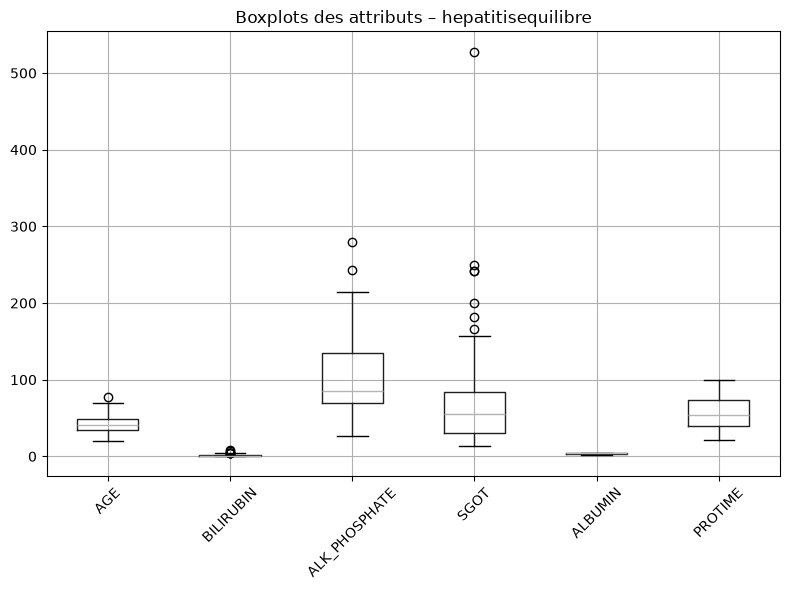

In [31]:
boxplots(df_hepatitisequilibre, "hepatitisequilibre")

### 5.4 Scatter plot

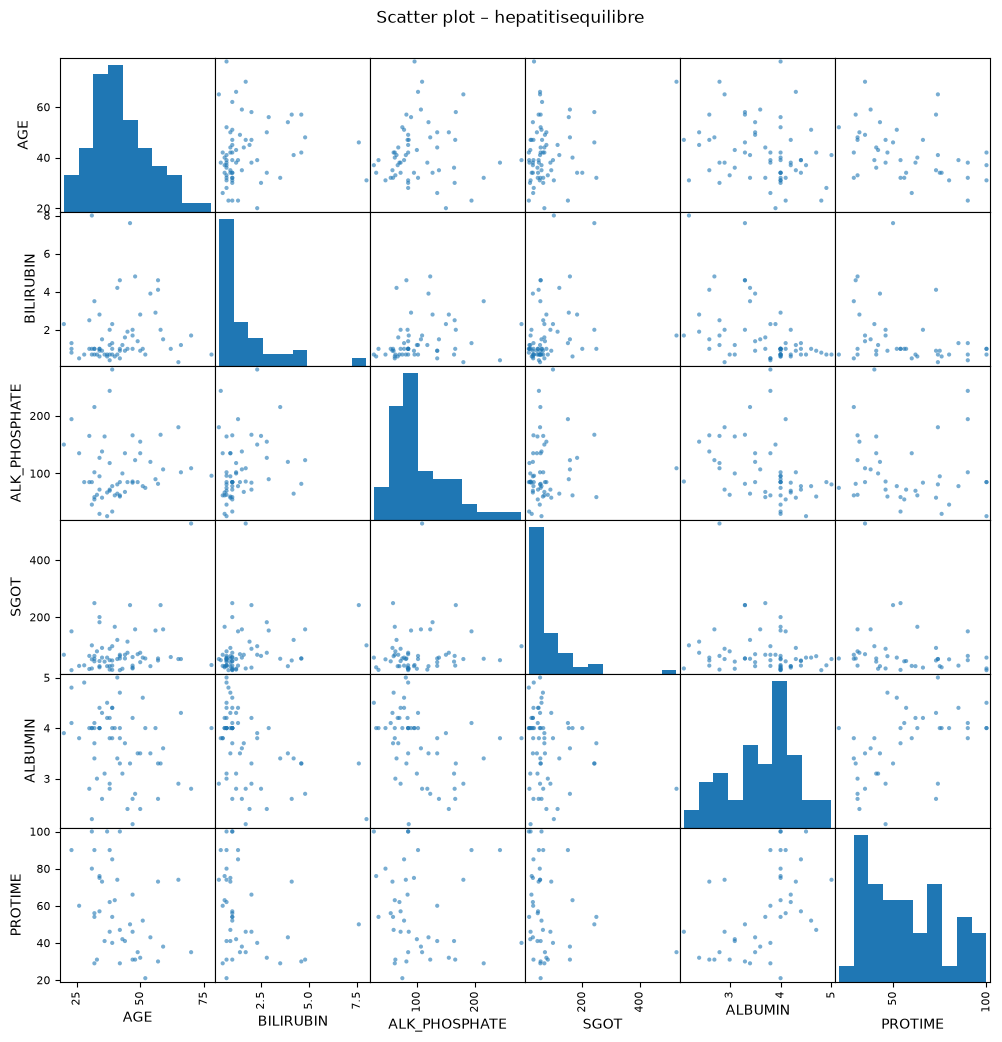

In [32]:
scatter(df_hepatitisequilibre, "hepatitisequilibre")

### 5.5 Valeurs manquantes : identification et remplacement

In [33]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_hepatitisequilibre))
df_hepatitisequilibre_imp = imputer(df_hepatitisequilibre)          # moyenne (numérique) / mode (catégoriel)
print("Total de valeurs manquantes après :", df_hepatitisequilibre_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage
STEROID,1,1.43
LIVER_BIG,5,7.14
LIVER_FIRM,5,7.14
SPLEEN_PALPABLE,1,1.43
SPIDERS,1,1.43
ASCITES,1,1.43
VARICES,1,1.43
BILIRUBIN,3,4.29
ALK_PHOSPHATE,13,18.57
SGOT,3,4.29


Total de valeurs manquantes après : 0


### 5.6 Normalisation (Min-Max et Z-score)

In [34]:
mm_hepatitisequilibre, zs_hepatitisequilibre = normaliser_predefini(df_hepatitisequilibre_imp)
print("Min-Max :"); display(mm_hepatitisequilibre.head())
print("Z-score :"); display(zs_hepatitisequilibre.head())

Min-Max :


,AGE,BILIRUBIN,ALK_PHOSPHATE,SGOT,ALBUMIN,PROTIME
0,0.672414,0.155844,0.318898,0.278210,0.517241,0.215190
1,0.637931,0.493506,0.308882,0.066148,0.172414,0.658228
2,0.586207,0.467532,0.370079,0.027237,0.482759,0.278481
3,0.534483,0.181818,0.308882,0.126169,0.536707,0.453047
4,0.482759,0.584416,0.381890,0.278210,0.206897,0.126582


Z-score :


,AGE,BILIRUBIN,ALK_PHOSPHATE,SGOT,ALBUMIN,PROTIME
0,1.430318,-1.325613e-01,5.511738e-02,1.010209e+00,-0.086415,-1.077642
1,1.260042,1.590735e+00,3.079042e-16,-3.987971e-01,-1.617199,0.929599
2,1.004628,1.458174e+00,3.367862e-01,-6.573303e-01,-0.239494,-0.790893
3,0.749214,1.471726e-16,3.079042e-16,1.836989e-16,0.000000,0.000000
4,0.493800,2.054699e+00,4.017867e-01,1.010209e+00,-1.464121,-1.479090


## 6. Dataset : iris  (`IRIS 1.csv`)


### 6.1 Lecture et informations de base


In [35]:
df_iris = charger("IRIS 1.csv")
display(df_iris)
infos_base(df_iris)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,3
146,6.3,2.5,5.0,1.9,3
147,6.5,3.0,5.2,2.0,3
148,6.2,3.4,5.4,2.3,3


Nombre d'instances (lignes) : 150
Nombre d'attributs (colonnes) : 5
Noms des attributs : ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Type de chaque attribut :
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species           int64
dtype: object


 ### 6.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode


In [36]:
stats_iris = stats_predefinies(df_iris)
stats_iris

,min,max,mediane,Q1,Q3,moyenne,mode
sepal_length,4.3,7.9,5.80,5.1,6.4,5.843333,5.0
sepal_width,2.0,4.4,3.00,2.8,3.3,3.054000,3.0
petal_length,1.0,6.9,4.35,1.6,5.1,3.758667,1.5
petal_width,0.1,2.5,1.30,0.3,1.8,1.198667,0.2
species,1.0,3.0,2.00,1.0,3.0,2.000000,1.0


 ### 6.3 Boxplots (tous les attributs sur le même graphique)
 

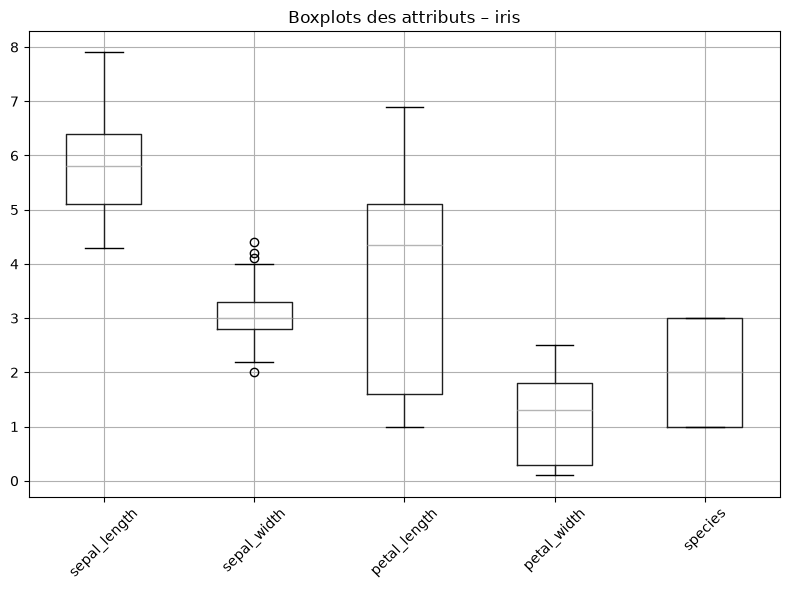

In [37]:
boxplots(df_iris, "iris")

### 6.4 Scatter plot


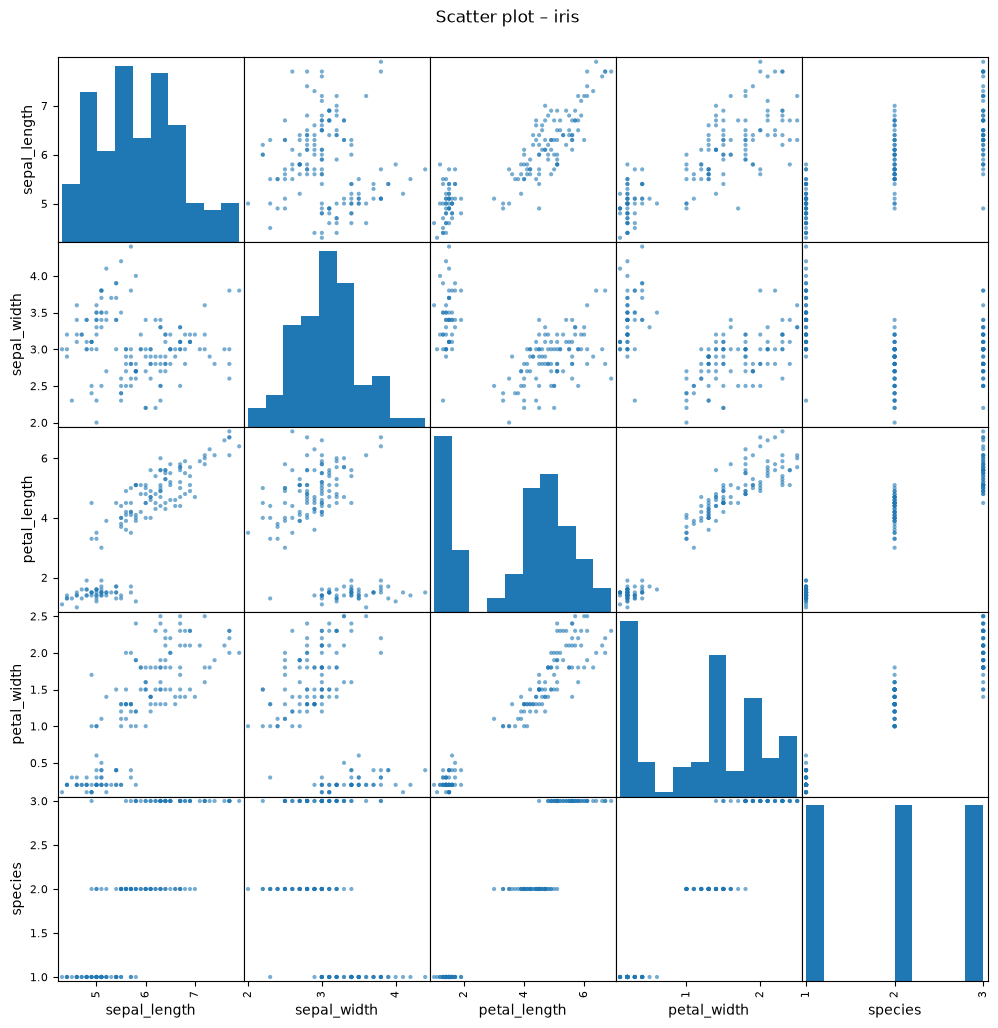

In [38]:
scatter(df_iris, "iris")

### 6.5 Valeurs manquantes : identification et remplacement

In [39]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_iris))
df_iris_imp = imputer(df_iris)
print("Total de valeurs manquantes après :", df_iris_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage


Total de valeurs manquantes après : 0


### 6.6 Normalisation (Min-Max et Z-score)

In [40]:
mm_iris, zs_iris = normaliser_predefini(df_iris_imp)
print("Min-Max :"); display(mm_iris.head())
print("Z-score :"); display(zs_iris.head())

Min-Max :


,sepal_length,sepal_width,petal_length,petal_width,species
0,0.222222,0.625000,0.067797,0.041667,0.0
1,0.166667,0.416667,0.067797,0.041667,0.0
2,0.111111,0.500000,0.050847,0.041667,0.0
3,0.083333,0.458333,0.084746,0.041667,0.0
4,0.194444,0.666667,0.067797,0.041667,0.0


Z-score :


,sepal_length,sepal_width,petal_length,petal_width,species
0,-0.900681,1.032057,-1.341272,-1.312977,-1.224745
1,-1.143017,-0.124958,-1.341272,-1.312977,-1.224745
2,-1.385353,0.337848,-1.398138,-1.312977,-1.224745
3,-1.506521,0.106445,-1.284407,-1.312977,-1.224745
4,-1.021849,1.263460,-1.341272,-1.312977,-1.224745


## 7. Dataset : breast  (`breast.csv`)

### 7.1 Lecture et informations de base

In [41]:
df_breast = charger("breast.csv")
display(df_breast.head())
infos_base(df_breast)

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,1


Nombre d'instances (lignes) : 500
Nombre d'attributs (colonnes) : 19
Noms des attributs : ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'diagnosis']

Type de chaque attribut :
radius_mean               float64
texture_mean              float64
perimeter_mean            float64
area_mean                 float64
smoothness_mean           float64
compactness_mean          float64
concavity_mean            float64
concave_points_mean       float64
symmetry_mean             float64
fractal_dimension_mean    float64
radius_se                 float64
texture_se                float64
perimeter_se              float64
area_se                   float64
smoothness_se             float64
compactness_se            float64
concavity_se  

### 7.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode

In [42]:
stats_breast = stats_predefinies(df_breast)
stats_breast

,min,max,mediane,Q1,Q3,moyenne,mode
radius_mean,6.981000,28.11000,13.435000,11.807500,16.115000,14.224206,11.60000
texture_mean,9.710000,39.28000,18.680000,16.070000,21.562500,19.086320,14.93000
perimeter_mean,43.790000,188.50000,86.735000,75.995000,106.225000,92.606620,82.61000
area_mean,143.500000,2501.00000,556.150000,430.550000,800.775000,662.844800,512.20000
smoothness_mean,0.062510,0.14470,0.095825,0.085992,0.105100,0.095978,0.10070
compactness_mean,0.019380,0.34540,0.091280,0.063622,0.130500,0.103948,0.11470
concavity_mean,0.000000,0.42680,0.064315,0.028885,0.132150,0.089941,0.00000
concave_points_mean,0.000000,0.20120,0.033870,0.020245,0.074928,0.049446,0.00000
symmetry_mean,0.116700,0.30400,0.179550,0.161875,0.195625,0.181370,0.16010
fractal_dimension_mean,0.049960,0.09744,0.061285,0.057607,0.065750,0.062497,0.05667


### 7.3 Boxplots (tous les attributs sur le même graphique)

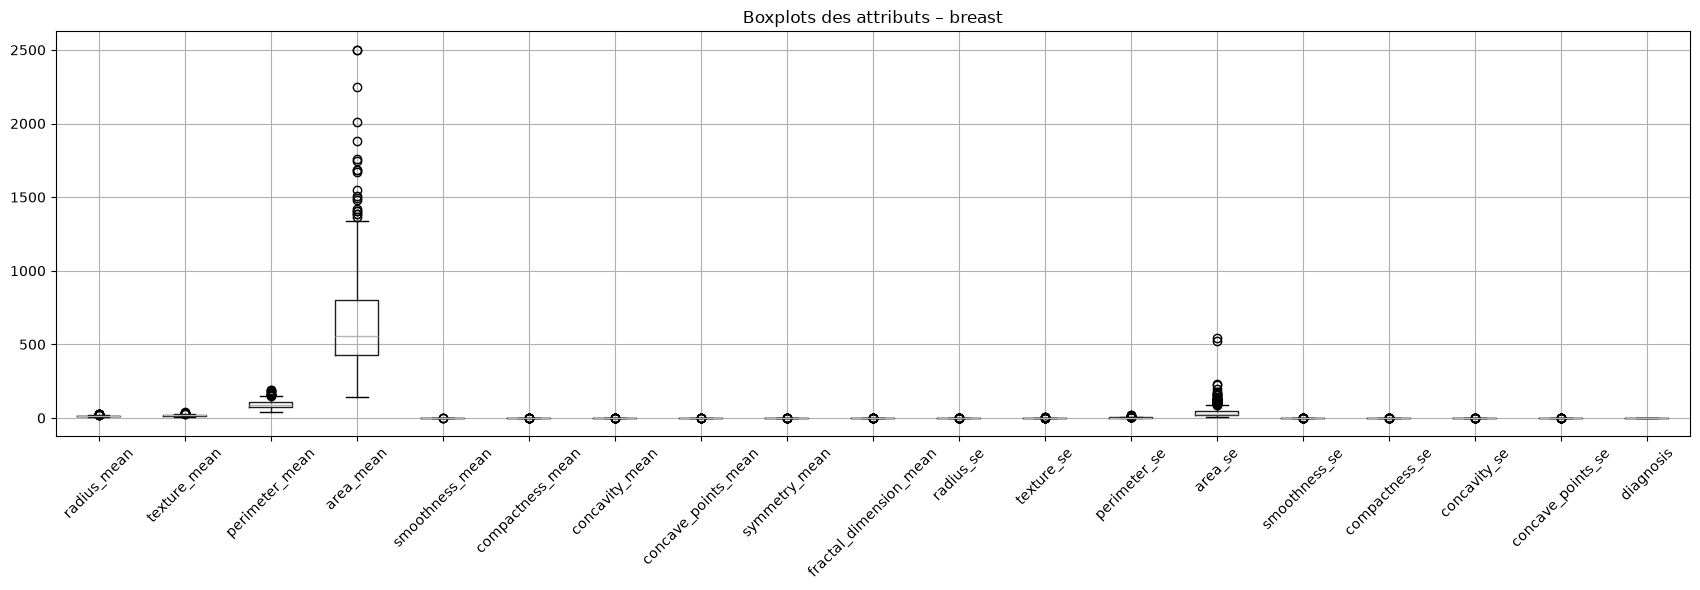

In [43]:
boxplots(df_breast, "breast")

### 7.4 Scatter plot

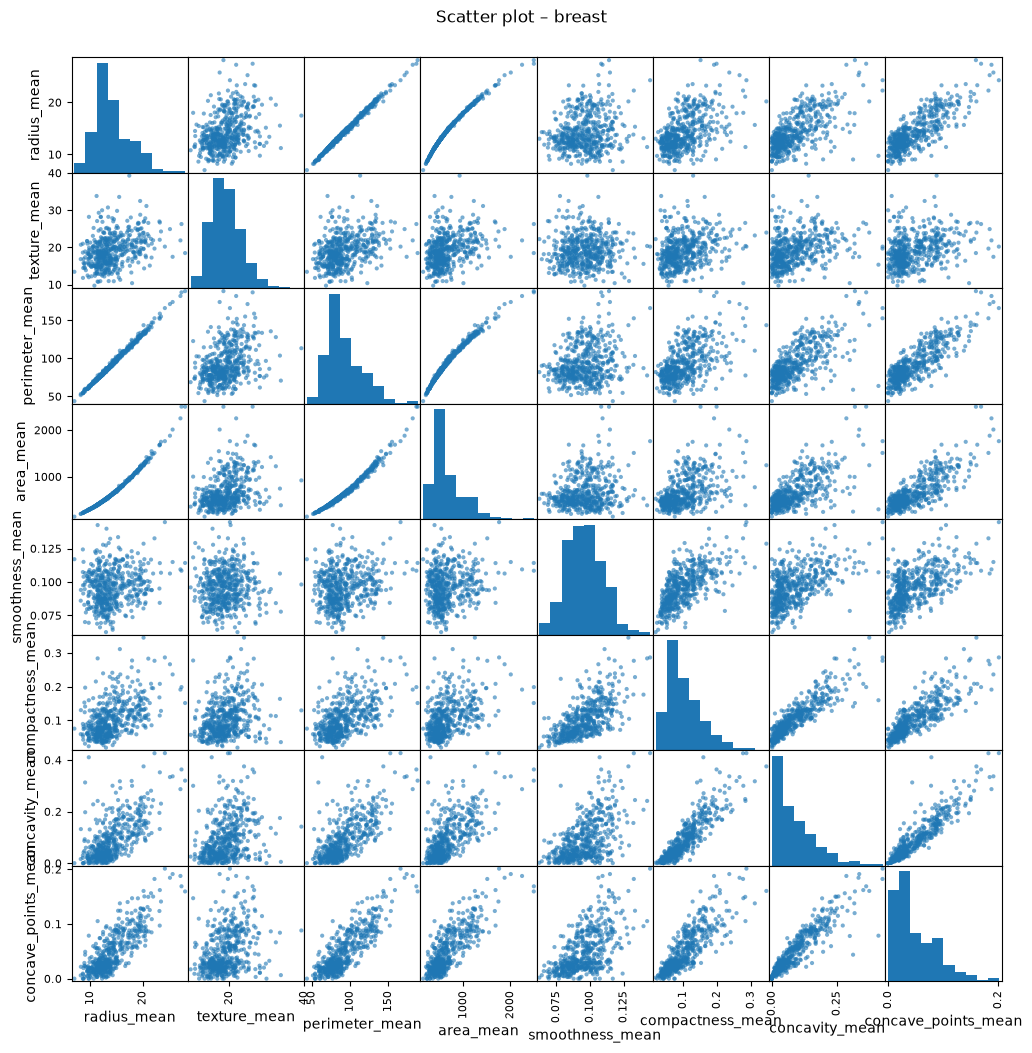

In [44]:
scatter(df_breast, "breast")

### 7.5 Valeurs manquantes : identification et remplacement

In [45]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_breast))
df_breast_imp = imputer(df_breast)
print("Total de valeurs manquantes après :", df_breast_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage


Total de valeurs manquantes après : 0


### 7.6 Normalisation (Min-Max et Z-score)

In [46]:
mm_breast, zs_breast = normaliser_predefini(df_breast_imp)
print("Min-Max :"); display(mm_breast.head())
print("Z-score :"); display(zs_breast.head())

Min-Max :


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,diagnosis
0,0.521037,0.022658,0.545989,0.363733,0.680010,0.792037,0.703140,0.731113,0.668446,0.605518,0.356147,0.120469,0.369034,0.273811,0.159296,0.351398,0.135682,0.300625,1.0
1,0.643144,0.272574,0.615783,0.501591,0.270471,0.181768,0.203608,0.348757,0.344367,0.141323,0.156437,0.082589,0.124440,0.125660,0.119387,0.081323,0.046970,0.253836,1.0
2,0.601496,0.390260,0.595743,0.449417,0.572941,0.431017,0.462512,0.635686,0.481580,0.211247,0.229622,0.094303,0.180370,0.162922,0.150831,0.283955,0.096768,0.389847,1.0
3,0.210090,0.360839,0.233501,0.102906,0.973233,0.811361,0.565604,0.522863,0.763481,1.000000,0.139091,0.175875,0.126655,0.038155,0.251453,0.543215,0.142955,0.353665,1.0
4,0.629893,0.156578,0.630986,0.489290,0.459788,0.347893,0.463918,0.518390,0.342766,0.186816,0.233822,0.093065,0.220563,0.163688,0.332359,0.167918,0.143636,0.357075,1.0


Z-score :


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,diagnosis
0,1.084203,-2.092526,1.260185,0.968905,1.642284,3.273826,2.621146,2.514512,2.186130,2.363520,2.431939,-0.548182,2.773660,2.406884,-0.181684,1.273042,0.689477,0.656891,1.250641
1,1.827006,-0.316372,1.681730,1.900116,-0.823159,-0.477121,-0.037927,0.533630,-0.006140,-0.849484,0.474716,-0.866924,0.244343,0.706411,-0.580826,-0.677640,-0.433062,0.258702,1.250641
2,1.573646,0.520031,1.560692,1.547688,0.997724,1.054855,1.340251,2.020129,0.922053,-0.365492,1.191951,-0.768363,0.822709,1.134102,-0.266340,0.785914,0.197068,1.416192,1.250641
3,-0.807354,0.310930,-0.627168,-0.792948,3.407500,3.392599,1.889028,1.435623,2.829003,5.093991,0.304723,-0.081970,0.267243,-0.297966,0.740015,2.658482,0.781504,1.108280,1.250641
4,1.746391,-1.140757,1.773552,1.817023,0.316541,0.543945,1.347734,1.412449,-0.016975,-0.534598,1.233118,-0.778777,1.238334,1.142891,1.549180,-0.052185,0.790132,1.137298,1.250641


## 8. Dataset : contact-lenses  (`contact-lenses.arff`)

### 8.1 Lecture et informations de base

In [47]:
df_contact = charger("contact-lenses.arff")
display(df_contact.head())
infos_base(df_contact)

,age,spectacle-prescrip,astigmatism,tear-prod-rate,contact-lenses
0,young,myope,no,reduced,none
1,young,myope,no,normal,soft
2,young,myope,yes,reduced,none
3,young,myope,yes,normal,hard
4,young,hypermetrope,no,reduced,none


Nombre d'instances (lignes) : 24
Nombre d'attributs (colonnes) : 5
Noms des attributs : ['age', 'spectacle-prescrip', 'astigmatism', 'tear-prod-rate', 'contact-lenses']

Type de chaque attribut :
age                   str
spectacle-prescrip    str
astigmatism           str
tear-prod-rate        str
contact-lenses        str
dtype: object


### 8.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode

In [48]:
stats_contact = stats_predefinies(df_contact)
stats_contact

,min,max,mediane,Q1,Q3,moyenne,mode


### 8.3 Boxplots (tous les attributs sur le même graphique)

In [49]:
boxplots(df_contact, "contact-lenses")

Dataset contact-lenses : aucun attribut numérique pour boxplot.


### 8.4 Scatter plot

In [50]:
scatter(df_contact, "contact-lenses")

Dataset contact-lenses : aucun attribut numérique pour scatter plot.


### 8.5 Valeurs manquantes : identification et remplacement

In [51]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_contact))
df_contact_imp = imputer(df_contact)
print("Total de valeurs manquantes après :", df_contact_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage


Total de valeurs manquantes après : 0


### 8.6 Normalisation (Min-Max et Z-score)

In [52]:
mm_contact, zs_contact = normaliser_predefini(df_contact_imp)
print("Min-Max :"); display(mm_contact.head())
print("Z-score :"); display(zs_contact.head())

Min-Max :


""


Z-score :


""


## 9. Dataset : horse-colic  (`horse-colic.csv`)

### 9.1 Lecture et informations de base

In [53]:
df_horse = charger("horse-colic.csv")
display(df_horse.head())
infos_base(df_horse)

,surgery,Age,Hospital Number,rectal temperature,pulse,respiratory rate,temperature of extremities,peripheral pulse,mucous membranes,capillary refill time,pain,peristalsis,abdominal distension,nasogastric tube,nasogastric reflux,nasogastric reflux PH,rectal examination,abdomen,packed cell volume,total protein,abdominocentesis appearance,abdomcentesis total protein,outcome,surgical lesion,type of lesion 1,type of lesion 2,type of lesion 3,cp_data
0,2.0,1,530101,38.5,66.0,28.0,3.0,3.0,NaN,2.0,5.0,4.0,4.0,NaN,NaN,NaN,3.0,5.0,45.0,8.4,NaN,NaN,2.0,2,11300,0,0,2
1,1.0,1,534817,39.2,88.0,20.0,NaN,NaN,4.0,1.0,3.0,4.0,2.0,NaN,NaN,NaN,4.0,2.0,50.0,85.0,2.0,2.0,3.0,2,2208,0,0,2
2,2.0,1,530334,38.3,40.0,24.0,1.0,1.0,3.0,1.0,3.0,3.0,1.0,NaN,NaN,NaN,1.0,1.0,33.0,6.7,NaN,NaN,1.0,2,0,0,0,1
3,1.0,9,5290409,39.1,164.0,84.0,4.0,1.0,6.0,2.0,2.0,4.0,4.0,1.0,2.0,5.0,3.0,NaN,48.0,7.2,3.0,5.3,2.0,1,2208,0,0,1
4,2.0,1,530255,37.3,104.0,35.0,NaN,NaN,6.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.0,7.4,NaN,NaN,2.0,2,4300,0,0,2


Nombre d'instances (lignes) : 300
Nombre d'attributs (colonnes) : 28
Noms des attributs : ['surgery', 'Age', 'Hospital Number', 'rectal temperature', 'pulse', 'respiratory rate', 'temperature of extremities', 'peripheral pulse', 'mucous membranes', 'capillary refill time', 'pain', 'peristalsis', 'abdominal distension', 'nasogastric tube', 'nasogastric reflux', 'nasogastric reflux PH', 'rectal examination', 'abdomen', 'packed cell volume', 'total protein', 'abdominocentesis appearance', 'abdomcentesis total protein', 'outcome', 'surgical lesion', 'type of lesion 1', 'type of lesion 2', 'type of lesion 3', 'cp_data']

Type de chaque attribut :
surgery                        float64
Age                              int64
Hospital Number                  int64
rectal temperature             float64
pulse                          float64
respiratory rate               float64
temperature of extremities     float64
peripheral pulse               float64
mucous membranes               float64

### 9.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode

In [54]:
stats_horse = stats_predefinies(df_horse)
stats_horse

,min,max,mediane,Q1,Q3,moyenne,mode
surgery,1.0,2.0,1.00,1.00,2.0,1.397993e+00,1.0
Age,1.0,9.0,1.00,1.00,1.0,1.640000e+00,1.0
Hospital Number,518476.0,5305629.0,530305.50,528904.00,534727.5,1.085889e+06,527544.0
rectal temperature,35.4,40.8,38.20,37.80,38.5,3.816792e+01,38.0
pulse,30.0,184.0,64.00,48.00,88.0,7.191304e+01,48.0
respiratory rate,8.0,96.0,24.50,18.50,36.0,3.041736e+01,20.0
temperature of extremities,1.0,4.0,3.00,1.00,3.0,2.348361e+00,3.0
peripheral pulse,1.0,4.0,2.00,1.00,3.0,2.017316e+00,1.0
mucous membranes,1.0,6.0,3.00,1.00,4.0,2.853755e+00,1.0
capillary refill time,1.0,3.0,1.00,1.00,2.0,1.305970e+00,1.0


### 9.3 Boxplots (tous les attributs sur le même graphique)

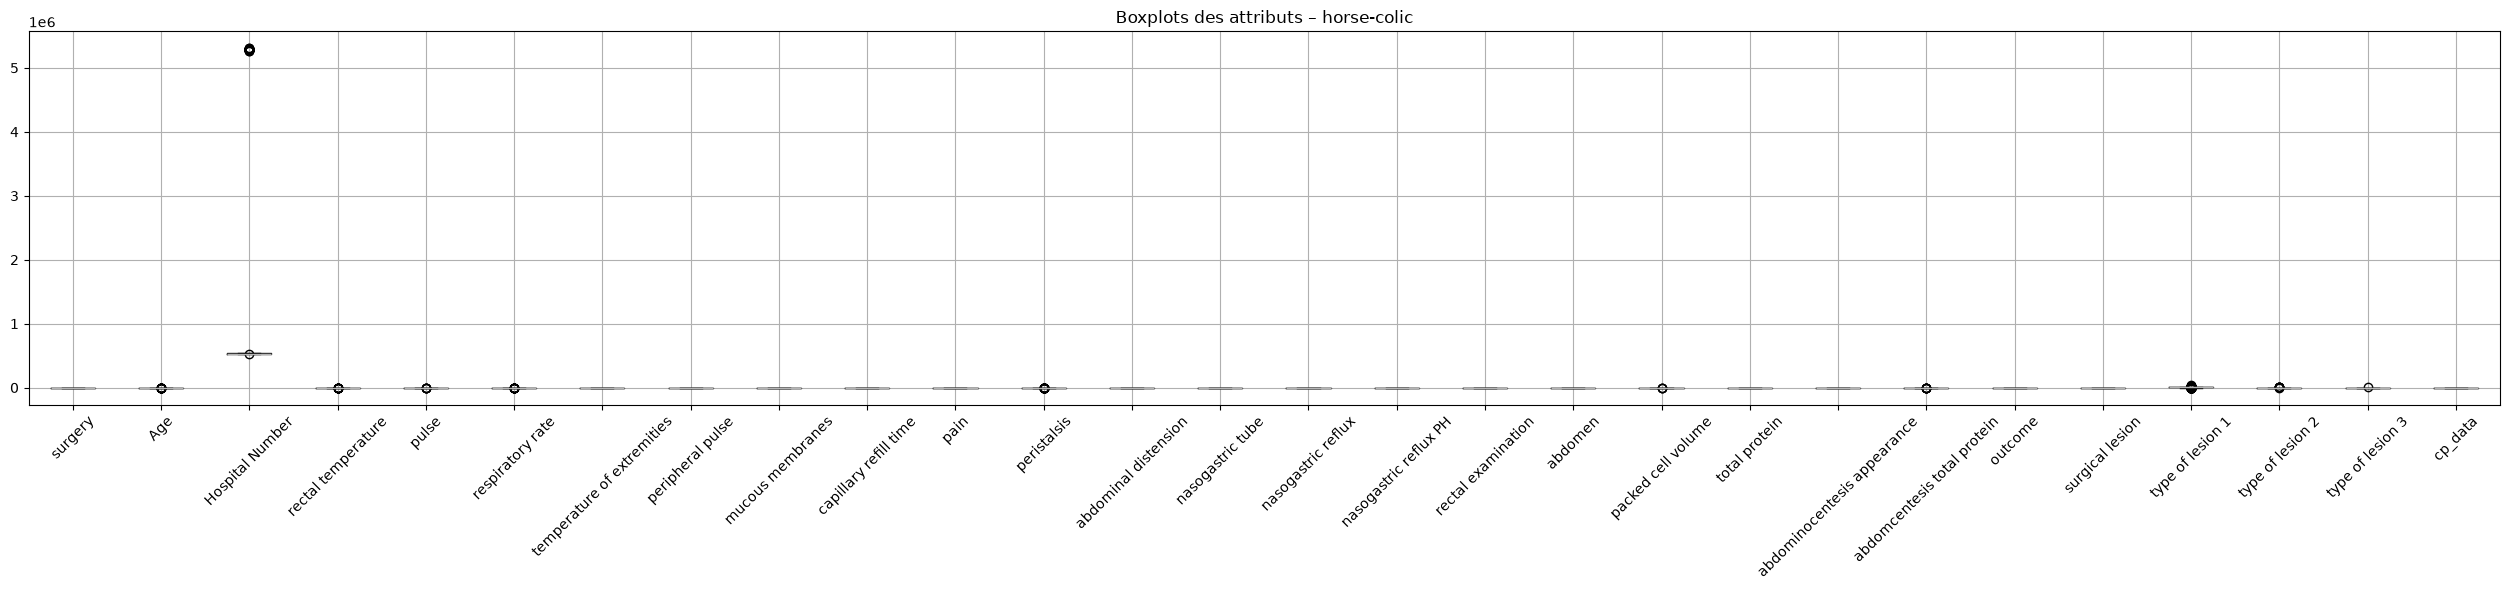

In [55]:
boxplots(df_horse, "horse-colic")

### 9.4 Scatter plot

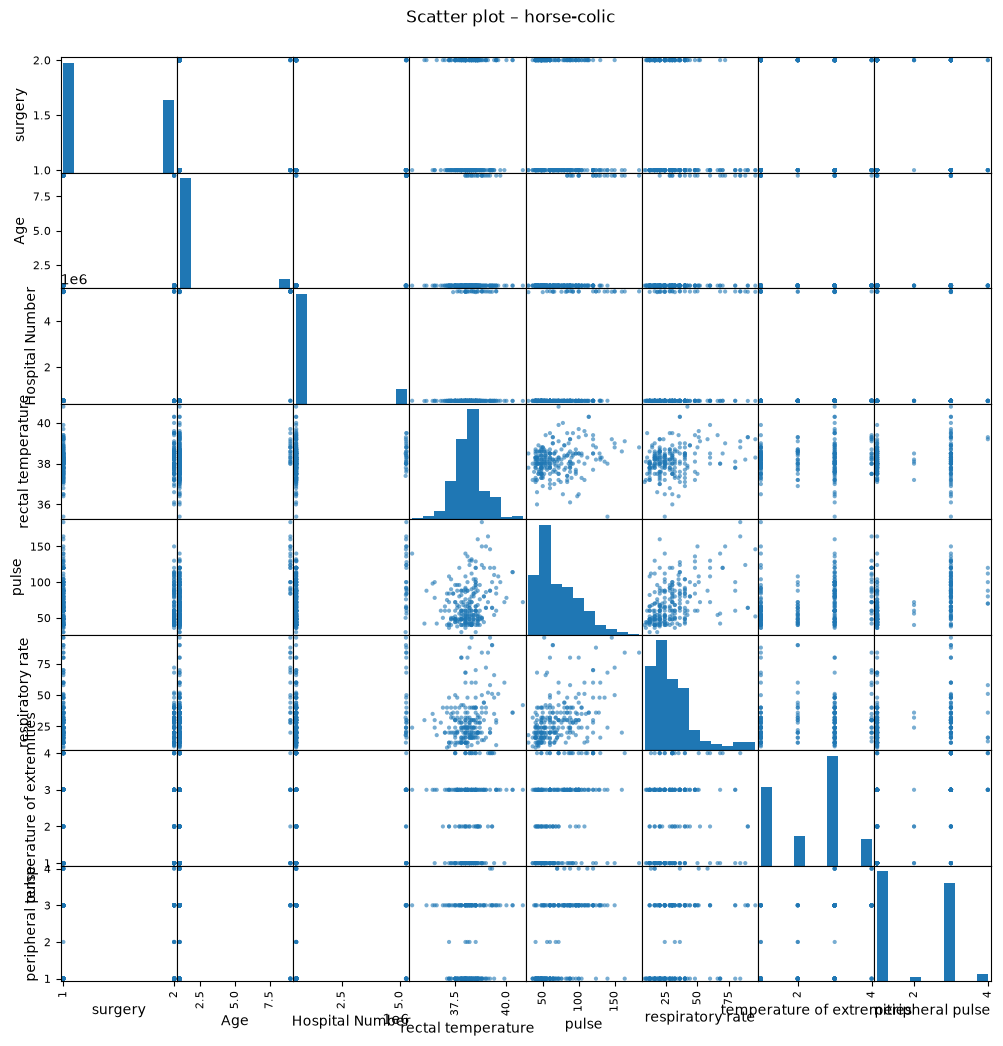

In [56]:
scatter(df_horse, "horse-colic")

### 9.5 Valeurs manquantes : identification et remplacement

In [57]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_horse))
df_horse_imp = imputer(df_horse)
print("Total de valeurs manquantes après :", df_horse_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage
surgery,1,0.33
rectal temperature,60,20.00
pulse,24,8.00
respiratory rate,58,19.33
temperature of extremities,56,18.67
peripheral pulse,69,23.00
mucous membranes,47,15.67
capillary refill time,32,10.67
pain,55,18.33
peristalsis,44,14.67


Total de valeurs manquantes après : 0


### 9.6 Normalisation (Min-Max et Z-score)

In [58]:
mm_horse, zs_horse = normaliser_predefini(df_horse_imp)
print("Min-Max :"); display(mm_horse.head())
print("Z-score :"); display(zs_horse.head())

Min-Max :


,surgery,Age,Hospital Number,rectal temperature,pulse,respiratory rate,temperature of extremities,peripheral pulse,mucous membranes,capillary refill time,pain,peristalsis,abdominal distension,nasogastric tube,nasogastric reflux,nasogastric reflux PH,rectal examination,abdomen,packed cell volume,total protein,abdominocentesis appearance,abdomcentesis total protein,outcome,surgical lesion,type of lesion 1,type of lesion 2,type of lesion 3,cp_data
0,1.0,0.0,0.002428,0.574074,0.233766,0.227273,0.666667,0.666667,0.370751,0.5,1.000000,1.000000,1.000000,0.377551,0.291237,0.570392,0.666667,1.000000,0.423077,0.059510,0.518519,0.291961,0.5,1.0,0.274872,0.0,0.0,1.0
1,0.0,0.0,0.003414,0.703704,0.376623,0.136364,0.449454,0.339105,0.600000,0.0,0.500000,1.000000,0.333333,0.377551,0.291237,0.570392,1.000000,0.250000,0.519231,0.953326,0.500000,0.190000,1.0,1.0,0.053710,0.0,0.0,1.0
2,1.0,0.0,0.002477,0.537037,0.064935,0.181818,0.000000,0.000000,0.400000,0.0,0.500000,0.666667,0.000000,0.377551,0.291237,0.570392,0.000000,0.000000,0.192308,0.039673,0.518519,0.291961,0.0,1.0,0.000000,0.0,0.0,0.0
3,0.0,1.0,0.996821,0.685185,0.870130,0.863636,1.000000,0.000000,1.000000,0.5,0.250000,1.000000,1.000000,0.000000,0.500000,0.615385,0.666667,0.673077,0.480769,0.045508,1.000000,0.520000,0.5,0.0,0.053710,0.0,0.0,0.0
4,1.0,0.0,0.002461,0.351852,0.480519,0.306818,0.449454,0.339105,1.000000,0.5,0.487755,0.639323,0.422131,0.377551,0.291237,0.570392,0.585859,0.673077,0.980769,0.047841,0.518519,0.291961,0.5,1.0,0.104597,0.0,0.0,1.0


Z-score :


,surgery,Age,Hospital Number,rectal temperature,pulse,respiratory rate,temperature of extremities,peripheral pulse,mucous membranes,capillary refill time,pain,peristalsis,abdominal distension,nasogastric tube,nasogastric reflux,nasogastric reflux PH,rectal examination,abdomen,packed cell volume,total protein,abdominocentesis appearance,abdomcentesis total protein,outcome,surgical lesion,type of lesion 1,type of lesion 2,type of lesion 3,cp_data
0,1.231935,-0.294884,-0.363914,0.508073,-0.215713,-0.152876,0.692829,1.076626,0.000000,1.540256,1.737063e+00,1.201571,1.808444,-8.481572e-16,0.000000,0.000000,2.391140e-01,1.128595e+00,-0.131032,-0.620647,-8.255320e-16,-3.887944e-16,0.609970,1.323742,1.417700,-0.139134,-0.057831,0.701810
1,-0.814446,-0.294884,-0.360826,1.579044,0.586865,-0.658804,0.000000,0.000000,0.771870,-0.679038,4.152343e-02,1.201571,-0.277893,-8.481572e-16,0.000000,0.000000,1.225460e+00,-1.460534e+00,0.374803,2.340165,-6.884937e-02,-8.926536e-01,1.971022,1.323742,-0.268969,-0.139134,-0.057831,0.701810
2,1.231935,-0.294884,-0.363762,0.202082,-1.164214,-0.405840,-1.433590,-1.114568,0.098480,-0.679038,4.152343e-02,0.091094,-1.321062,-8.481572e-16,0.000000,0.000000,-1.733577e+00,-2.323578e+00,-1.345035,-0.686357,-8.255320e-16,-3.887944e-16,-0.751082,1.323742,-0.678578,-0.139134,-0.057831,-1.424887
3,-0.814446,3.391165,2.753002,1.426048,3.359407,3.388619,1.756039,-1.114568,2.118649,1.540256,-8.062466e-01,1.201571,1.808444,-1.442154e+00,0.646362,0.354359,2.391140e-01,3.832681e-16,0.172469,-0.667030,1.790084e+00,1.996454e+00,0.609970,-0.755434,-0.268969,-0.139134,-0.057831,-1.424887
4,1.231935,-0.294884,-0.363813,-1.327876,1.170558,0.289811,0.000000,0.000000,2.118649,1.540256,-3.764855e-16,0.000000,0.000000,-8.481572e-16,0.000000,0.000000,4.380254e-16,3.832681e-16,2.802810,-0.659300,-8.255320e-16,-3.887944e-16,0.609970,1.323742,0.119121,-0.139134,-0.057831,0.701810


## 10. Dataset : hypothyroid  (`hypothyroid.arff`)

### 10.1 Lecture et informations de base

In [59]:
df_hypothyroid = charger("hypothyroid.arff")
display(df_hypothyroid.head())
infos_base(df_hypothyroid)

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,query hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH measured,TSH,T3 measured,T3,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,Class
0,41.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.30,t,2.5,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,negative
1,23.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,4.10,t,2.0,t,102.0,f,NaN,f,NaN,f,NaN,other,negative
2,46.0,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.98,f,NaN,t,109.0,t,0.91,t,120.0,f,NaN,other,negative
3,70.0,F,t,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.16,t,1.9,t,175.0,f,NaN,f,NaN,f,NaN,other,negative
4,70.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.72,t,1.2,t,61.0,t,0.87,t,70.0,f,NaN,SVI,negative


Nombre d'instances (lignes) : 3772
Nombre d'attributs (colonnes) : 30
Noms des attributs : ['age', 'sex', 'on thyroxine', 'query on thyroxine', 'on antithyroid medication', 'sick', 'pregnant', 'thyroid surgery', 'I131 treatment', 'query hypothyroid', 'query hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH measured', 'TSH', 'T3 measured', 'T3', 'TT4 measured', 'TT4', 'T4U measured', 'T4U', 'FTI measured', 'FTI', 'TBG measured', 'TBG', 'referral source', 'Class']

Type de chaque attribut :
age                          float64
sex                              str
on thyroxine                     str
query on thyroxine               str
on antithyroid medication        str
sick                             str
pregnant                         str
thyroid surgery                  str
I131 treatment                   str
query hypothyroid                str
query hyperthyroid               str
lithium                          str
goitre                           str

### 10.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode

In [60]:
stats_hypothyroid = stats_predefinies(df_hypothyroid)
stats_hypothyroid

,min,max,mediane,Q1,Q3,moyenne,mode
age,1.000,455.00,54.00,36.00,67.00,51.735879,59.00
TSH,0.005,530.00,1.40,0.50,2.70,5.086766,0.20
T3,0.050,10.60,2.00,1.60,2.40,2.013500,2.00
TT4,2.000,430.00,103.00,88.00,124.00,108.319345,101.00
T4U,0.250,2.32,0.98,0.88,1.08,0.995000,0.99
FTI,2.000,395.00,107.00,93.00,124.00,110.469649,100.00
TBG,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 10.3 Boxplots (tous les attributs sur le même graphique)

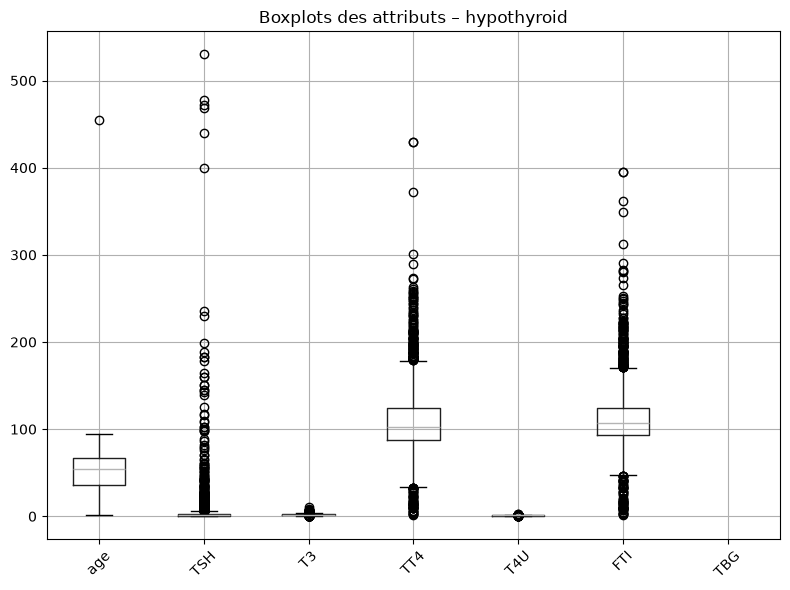

In [61]:
boxplots(df_hypothyroid, "hypothyroid")

### 10.4 Scatter plot

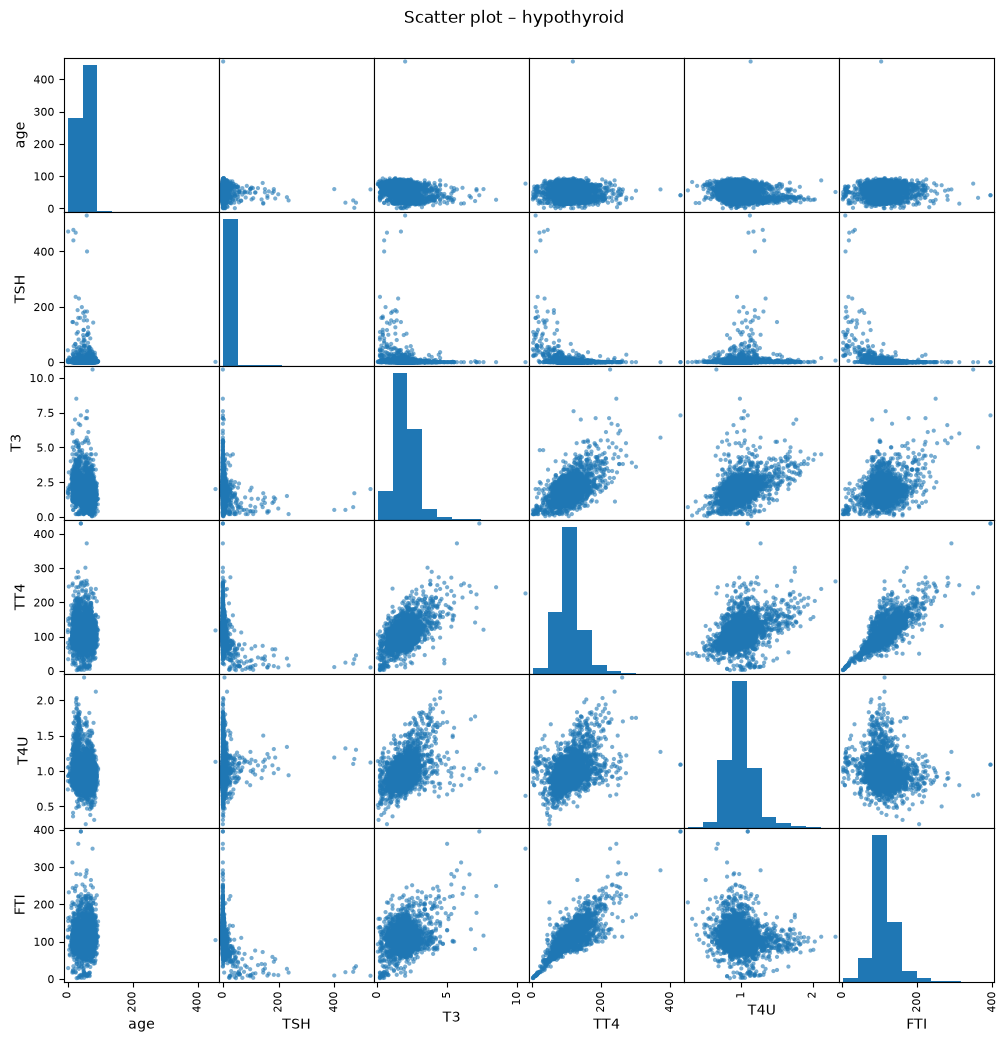

In [62]:
scatter(df_hypothyroid, "hypothyroid")

### 10.5 Valeurs manquantes : identification et remplacement

In [63]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_hypothyroid))
df_hypothyroid_imp = imputer(df_hypothyroid)
print("Total de valeurs manquantes après :", df_hypothyroid_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage
age,1,0.03
sex,150,3.98
TSH,369,9.78
T3,769,20.39
TT4,231,6.12
T4U,387,10.26
FTI,385,10.21
TBG,3772,100.00


Colonnes entièrement vides supprimées : ['TBG']
Total de valeurs manquantes après : 0


### 10.6 Normalisation (Min-Max et Z-score)

In [64]:
mm_hypothyroid, zs_hypothyroid = normaliser_predefini(df_hypothyroid_imp)
print("Min-Max :"); display(mm_hypothyroid.head())
print("Z-score :"); display(zs_hypothyroid.head())

Min-Max :


,age,TSH,T3,TT4,T4U,FTI
0,0.088106,0.002443,0.232227,0.287383,0.429952,0.272265
1,0.048458,0.007726,0.184834,0.233645,0.359903,0.276004
2,0.099119,0.001840,0.186114,0.250000,0.318841,0.300254
3,0.151982,0.000292,0.175355,0.404206,0.359903,0.276004
4,0.151982,0.001349,0.109005,0.137850,0.299517,0.173028


Z-score :


,age,TSH,T3,TT4,T4U,FTI
0,-0.534665,-0.162608,6.590677e-01,0.483610,7.832271e-01,-0.046877
1,-1.431096,-0.042373,-1.828839e-02,-0.183212,-5.996931e-16,0.000000
2,-0.285657,-0.176349,6.016131e-16,0.019734,-4.591306e-01,0.303989
3,0.909584,-0.211560,-1.537596e-01,1.933224,-5.996931e-16,0.000000
4,0.909584,-0.187513,-1.102058e+00,-1.371896,-6.751928e-01,-1.290860


## 11. Dataset : lymph  (`lymph.arff`)

### 11.1 Lecture et informations de base

In [65]:
df_lymph = charger("lymph.arff")
display(df_lymph.head())
infos_base(df_lymph)

,lymphatics,block_of_affere,bl_of_lymph_c,bl_of_lymph_s,by_pass,extravasates,regeneration_of,early_uptake_in,lym_nodes_dimin,lym_nodes_enlar,changes_in_lym,defect_in_node,changes_in_node,changes_in_stru,special_forms,dislocation_of,exclusion_of_no,no_of_nodes_in,class
0,arched,yes,no,no,no,no,no,yes,1.0,4.0,round,lac_central,lacunar,stripped,vesicles,yes,yes,5.0,malign_lymph
1,displaced,yes,no,no,yes,yes,no,yes,1.0,3.0,round,lac_central,lacunar,diluted,vesicles,yes,yes,3.0,malign_lymph
2,deformed,no,no,no,yes,yes,yes,no,3.0,1.0,bean,lacunar,no,diluted,vesicles,no,no,7.0,fibrosis
3,arched,no,no,no,no,yes,no,yes,1.0,2.0,oval,lac_margin,lac_margin,drop_like,vesicles,no,yes,1.0,malign_lymph
4,arched,no,no,no,no,no,no,no,1.0,2.0,round,lac_margin,lac_margin,faint,vesicles,no,no,1.0,metastases


Nombre d'instances (lignes) : 148
Nombre d'attributs (colonnes) : 19
Noms des attributs : ['lymphatics', 'block_of_affere', 'bl_of_lymph_c', 'bl_of_lymph_s', 'by_pass', 'extravasates', 'regeneration_of', 'early_uptake_in', 'lym_nodes_dimin', 'lym_nodes_enlar', 'changes_in_lym', 'defect_in_node', 'changes_in_node', 'changes_in_stru', 'special_forms', 'dislocation_of', 'exclusion_of_no', 'no_of_nodes_in', 'class']

Type de chaque attribut :
lymphatics             str
block_of_affere        str
bl_of_lymph_c          str
bl_of_lymph_s          str
by_pass                str
extravasates           str
regeneration_of        str
early_uptake_in        str
lym_nodes_dimin    float64
lym_nodes_enlar    float64
changes_in_lym         str
defect_in_node         str
changes_in_node        str
changes_in_stru        str
special_forms          str
dislocation_of         str
exclusion_of_no        str
no_of_nodes_in     float64
class                  str
dtype: object


### 11.2 Statistiques : min, max, médiane, Q1, Q3, moyenne, mode

In [66]:
stats_lymph = stats_predefinies(df_lymph)
stats_lymph

,min,max,mediane,Q1,Q3,moyenne,mode
lym_nodes_dimin,1.0,3.0,1.0,1.0,1.0,1.060811,1.0
lym_nodes_enlar,1.0,4.0,2.0,2.0,3.0,2.472973,2.0
no_of_nodes_in,1.0,8.0,2.0,1.0,3.0,2.601351,1.0


### 11.3 Boxplots (tous les attributs sur le même graphique)

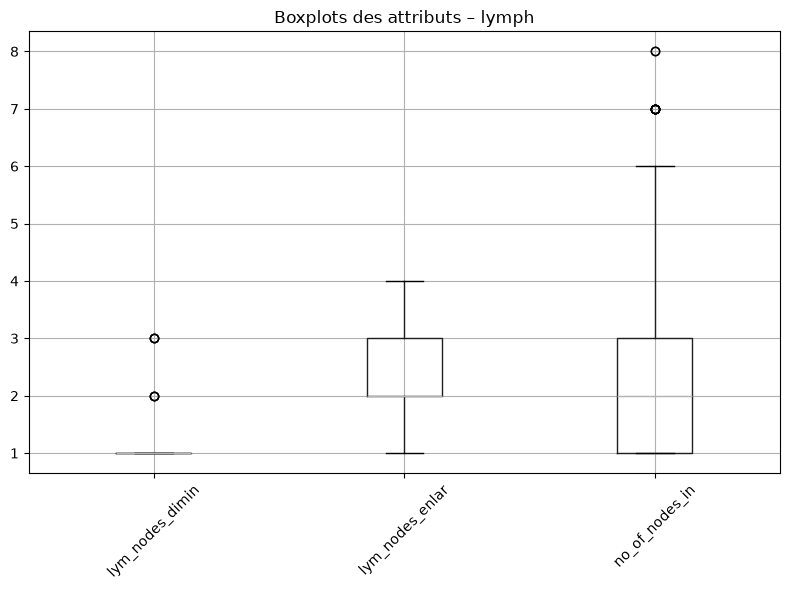

In [67]:
boxplots(df_lymph, "lymph")

### 11.4 Scatter plot

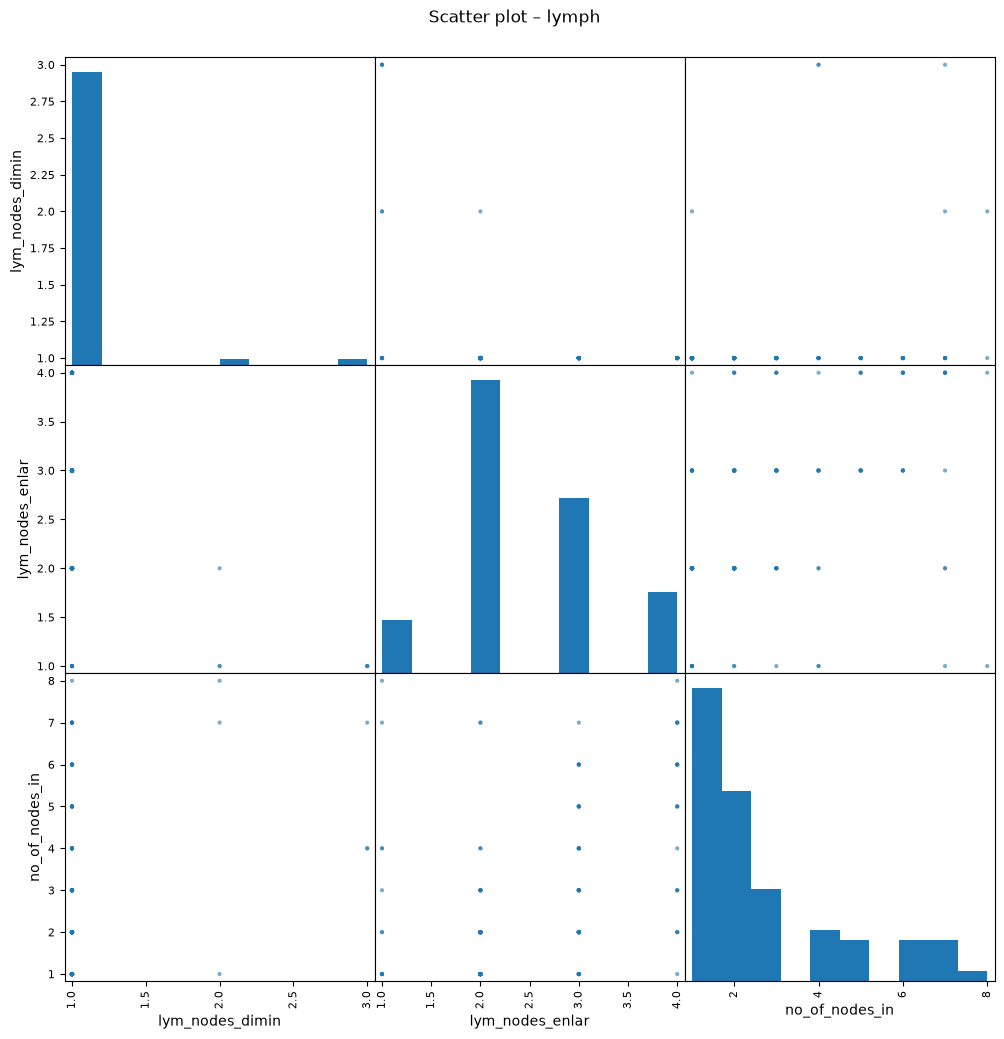

In [68]:
scatter(df_lymph, "lymph")

### 11.5 Valeurs manquantes : identification et remplacement

In [69]:
print("Valeurs manquantes avant :")
display(valeurs_manquantes(df_lymph))
df_lymph_imp = imputer(df_lymph)
print("Total de valeurs manquantes après :", df_lymph_imp.isna().sum().sum())

Valeurs manquantes avant :


,nb_manquantes,pourcentage


Total de valeurs manquantes après : 0


### 11.6 Normalisation (Min-Max et Z-score)

In [70]:
mm_lymph, zs_lymph = normaliser_predefini(df_lymph_imp)
print("Min-Max :"); display(mm_lymph.head())
print("Z-score :"); display(zs_lymph.head())

Min-Max :


,lym_nodes_dimin,lym_nodes_enlar,no_of_nodes_in
0,0.0,1.000000,0.571429
1,0.0,0.666667,0.285714
2,1.0,0.000000,0.857143
3,0.0,0.333333,0.000000
4,0.0,0.333333,0.000000


Z-score :


,lym_nodes_dimin,lym_nodes_enlar,no_of_nodes_in
0,-0.194597,1.831416,1.263393
1,-0.194597,0.632082,0.209972
2,6.205496,-1.766587,2.316814
3,-0.194597,-0.567253,-0.843448
4,-0.194597,-0.567253,-0.843448
